# LifeMap AI Diabetes Module: Live Evaluation Report
Comprehensive empirical evaluation computed live across NHANES (2013-2018) and CDC BRFSS (2015).

# P1. NHANES Tier 1 Dataset Preview
Processed adult cohort with 10 non-invasive features.

In [1]:
import pandas as pd
df1 = pd.read_csv('../../data/processed/nhanes_diabetes_processed.csv')
cols1 = ['age', 'sex', 'bmi', 'mean_sbp', 'mean_dbp', 'high_bp', 'high_chol', 'smoker', 'phys_activity', 'family_history', 'diabetes']
df1_sub = df1[cols1]
n1, k1 = df1_sub.shape
c0_1, c1_1 = int((df1_sub['diabetes'] == 0).sum()), int((df1_sub['diabetes'] == 1).sum())
print(f"Dataset Shape: {n1:,} patient samples, {k1} columns ({k1-1} features + 1 outcome)")
print(f"Class Distribution: Negative (0) = {c0_1:,} ({c0_1/n1*100:.1f}%), Positive (1) = {c1_1:,} ({c1_1/n1*100:.1f}%)")
df1_sub.head()

Dataset Shape: 17,468 patient samples, 11 columns (10 features + 1 outcome)
Class Distribution: Negative (0) = 15,019 (86.0%), Positive (1) = 2,449 (14.0%)


,age,sex,bmi,mean_sbp,mean_dbp,high_bp,high_chol,smoker,phys_activity,family_history,diabetes
0,69.0,1,26.7,112.666667,74.000000,1.0,1.0,1.0,0.0,1.0,1
1,54.0,1,28.6,157.333333,61.333333,1.0,1.0,1.0,1.0,1.0,1
2,72.0,1,28.9,142.000000,82.000000,1.0,1.0,1.0,1.0,0.0,1
3,73.0,0,19.7,137.333333,86.666667,1.0,0.0,0.0,1.0,0.0,0
4,56.0,1,41.7,157.333333,82.000000,1.0,1.0,1.0,1.0,0.0,0


# P2. NHANES Tier 2 Dataset Preview
Lab-augmented cohort with glycated hemoglobin (HbA1c).

In [2]:
import pandas as pd
df2 = pd.read_csv('../../data/processed/tier2_nhanes_with_hba1c.csv')
cols2 = ['age', 'sex', 'bmi', 'mean_sbp', 'mean_dbp', 'high_bp', 'high_chol', 'smoker', 'phys_activity', 'family_history', 'hba1c', 'diabetes']
df2_sub = df2.dropna(subset=['hba1c'])[cols2].reset_index(drop=True)
n2, k2 = df2_sub.shape
c0_2, c1_2 = int((df2_sub['diabetes'] == 0).sum()), int((df2_sub['diabetes'] == 1).sum())
print(f"Dataset Shape: {n2:,} patient samples, {k2} columns ({k2-1} features + 1 outcome)")
print(f"Class Distribution: Negative (0) = {c0_2:,} ({c0_2/n2*100:.1f}%), Positive (1) = {c1_2:,} ({c1_2/n2*100:.1f}%)")
df2_sub.head()

Dataset Shape: 15,936 patient samples, 12 columns (11 features + 1 outcome)
Class Distribution: Negative (0) = 13,658 (85.7%), Positive (1) = 2,278 (14.3%)


,age,sex,bmi,mean_sbp,mean_dbp,high_bp,high_chol,smoker,phys_activity,family_history,hba1c,diabetes
0,69.0,1,26.7,112.666667,74.000000,1.0,1.0,1.0,0.0,1.0,13.9,1
1,54.0,1,28.6,157.333333,61.333333,1.0,1.0,1.0,1.0,1.0,9.1,1
2,72.0,1,28.9,142.000000,82.000000,1.0,1.0,1.0,1.0,0.0,8.9,1
3,73.0,0,19.7,137.333333,86.666667,1.0,0.0,0.0,1.0,0.0,4.9,0
4,56.0,1,41.7,157.333333,82.000000,1.0,1.0,1.0,1.0,0.0,5.5,0


# P3. BRFSS 2015 Shared Dataset Preview
CDC behavioral surveillance cohort for external testing.

In [3]:
import pandas as pd
df3 = pd.read_csv('../../data/processed/brfss_diabetes_processed.csv')
cols3 = ['age_bucket', 'sex', 'bmi', 'high_bp', 'high_chol', 'smoker', 'phys_activity', 'diabetes']
df3_sub = df3[cols3]
n3, k3 = df3_sub.shape
c0_3, c1_3 = int((df3_sub['diabetes'] == 0).sum()), int((df3_sub['diabetes'] == 1).sum())
print(f"Dataset Shape: {n3:,} patient samples, {k3} columns ({k3-1} features + 1 outcome)")
print(f"Class Distribution: Negative (0) = {c0_3:,} ({c0_3/n3*100:.1f}%), Positive (1) = {c1_3:,} ({c1_3/n3*100:.1f}%)")
df3_sub.head()

Dataset Shape: 249,049 patient samples, 8 columns (7 features + 1 outcome)
Class Distribution: Negative (0) = 213,703 (85.8%), Positive (1) = 35,346 (14.2%)


,age_bucket,sex,bmi,high_bp,high_chol,smoker,phys_activity,diabetes
0,9.0,0.0,40.0,1.0,1.0,1.0,0.0,0
1,7.0,0.0,25.0,0.0,0.0,1.0,1.0,0
2,9.0,0.0,28.0,1.0,1.0,0.0,0.0,0
3,11.0,0.0,27.0,1.0,0.0,0.0,1.0,0
4,11.0,0.0,24.0,1.0,1.0,0.0,1.0,0


# P4. Previous Baseline Dataset Preview
Different dataset and features from the new system; results are not directly comparable.

In [4]:
import json, pandas as pd
df4 = pd.read_csv('../../data/pima_indians_diabetes.csv')
n4, k4 = df4.shape
c0_4, c1_4 = int((df4['Outcome'] == 0).sum()), int((df4['Outcome'] == 1).sum())
print(f"Dataset Shape: {n4:,} patient samples, {k4} columns ({k4-1} features + 1 outcome)")
print(f"Class Distribution: Negative (0) = {c0_4:,} ({c0_4/n4*100:.1f}%), Positive (1) = {c1_4:,} ({c1_4/n4*100:.1f}%)")
display(df4.head())
with open('../experiments/pima_baseline/pima_results.json') as f:
    print("Saved Pima Baseline Results:")
    print(json.dumps(json.load(f), indent=2))

Dataset Shape: 768 patient samples, 9 columns (8 features + 1 outcome)
Class Distribution: Negative (0) = 500 (65.1%), Positive (1) = 268 (34.9%)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Saved Pima Baseline Results:
{
  "dataset": "Pima Indians Diabetes",
  "n_samples": 768,
  "n_features": 8,
  "features": [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age"
  ],
  "accuracy": 0.7532467532467533,
  "balanced_accuracy": 0.7333333333333334,
  "precision": 0.6428571428571429,
  "recall": 0.6666666666666666,
  "f1": 0.6545454545454545,
  "roc_auc": 0.8214814814814815,
  "pr_auc": 0.725454194584976,
  "brier_score": 0.1654642857142857
}


# P5. Tier 1 Data Types Audit
Column data types and missing value counts for Tier 1.

In [5]:
import pandas as pd
df1 = pd.read_csv('../../data/processed/nhanes_diabetes_processed.csv')
cols1 = ['age', 'sex', 'bmi', 'mean_sbp', 'mean_dbp', 'high_bp', 'high_chol', 'smoker', 'phys_activity', 'family_history', 'diabetes']
audit = pd.DataFrame({'Data Type': df1[cols1].dtypes, 'Missing Count': df1[cols1].isna().sum()})
display(audit)

,Data Type,Missing Count
age,float64,0
sex,int64,0
bmi,float64,993
mean_sbp,float64,1385
mean_dbp,float64,1385
high_bp,float64,21
high_chol,float64,106
smoker,float64,11
phys_activity,float64,0
family_history,float64,1196


# A1. Datasets at a Glance
Key cohort dimensions and class distributions across surveys.

In [6]:
import pandas as pd
df_nh = pd.read_csv('../../data/processed/nhanes_diabetes_processed.csv')
df_br = pd.read_csv('../../data/processed/brfss_diabetes_processed.csv')
n_nh, n_br = len(df_nh), len(df_br)
d_nh, nd_nh = int(df_nh['diabetes'].sum()), n_nh - int(df_nh['diabetes'].sum())
d_br, nd_br = int(df_br['diabetes'].sum()), n_br - int(df_br['diabetes'].sum())
a1_df = pd.DataFrame([
    {'Dataset': 'NHANES (2013-2018)', 'Cycles': '3 cycles (H, I, J)', 'Total Rows': n_nh, 'Diabetic': d_nh, 'Non-Diabetic': nd_nh, '% Diabetic': f'{d_nh/n_nh*100:.2f}%', 'Imbalance Ratio': f'1:{nd_nh/d_nh:.2f}', 'Features': '10 (Tier 1) / 11 (Tier 2)'},
    {'Dataset': 'CDC BRFSS (2015)', 'Cycles': '2015 Annual Survey', 'Total Rows': n_br, 'Diabetic': d_br, 'Non-Diabetic': nd_br, '% Diabetic': f'{d_br/n_br*100:.2f}%', 'Imbalance Ratio': f'1:{nd_br/d_br:.2f}', 'Features': '7 (Shared-7)'}
])
a1_df.to_csv('../reports/paper/tables/dataset_overview.csv', index=False)
display(a1_df.style.hide(axis='index'))

Dataset,Cycles,Total Rows,Diabetic,Non-Diabetic,% Diabetic,Imbalance Ratio,Features
NHANES (2013-2018),"3 cycles (H, I, J)",17468,2449,15019,14.02%,1:6.13,10 (Tier 1) / 11 (Tier 2)
CDC BRFSS (2015),2015 Annual Survey,249049,35346,213703,14.19%,1:6.05,7 (Shared-7)


# A2. NHANES Cohort Flow Funnel
Participant attrition from raw demographics to final cohort.

In [7]:
import pandas as pd
cycles = {'2013-2014 (H)': 'H', '2015-2016 (I)': 'I', '2017-2018 (J)': 'J'}
rows = []
for cname, c in cycles.items():
    demo = pd.read_sas(f'../../data/raw/nhanes/DEMO_{c}.xpt')
    diq = pd.read_sas(f'../../data/raw/nhanes/DIQ_{c}.xpt')[['SEQN', 'DIQ010']]
    adults = demo[demo['RIDAGEYR'] >= 18]
    m = adults.merge(diq, on='SEQN', how='inner')
    ret = m[m['DIQ010'].isin([1.0, 2.0])]
    rows.append({'Cycle': cname, 'Total DEMO': len(demo), 'Adults (>=18)': len(adults), 'Under 18 Dropped': len(demo)-len(adults), 'Valid DIQ010': len(m), 'Borderline/Refused Dropped': len(m)-len(ret), 'Final Retained': len(ret), 'Diabetic': int((ret['DIQ010']==1).sum()), 'Non-Diabetic': int((ret['DIQ010']==2).sum())})
tot = pd.DataFrame(rows)
rows.append({'Cycle': 'Pooled Total', 'Total DEMO': tot['Total DEMO'].sum(), 'Adults (>=18)': tot['Adults (>=18)'].sum(), 'Under 18 Dropped': tot['Under 18 Dropped'].sum(), 'Valid DIQ010': tot['Valid DIQ010'].sum(), 'Borderline/Refused Dropped': tot['Borderline/Refused Dropped'].sum(), 'Final Retained': tot['Final Retained'].sum(), 'Diabetic': tot['Diabetic'].sum(), 'Non-Diabetic': tot['Non-Diabetic'].sum()})
a2_df = pd.DataFrame(rows)
a2_df.to_csv('../reports/paper/tables/nhanes_funnel.csv', index=False)
display(a2_df.style.hide(axis='index'))

Cycle,Total DEMO,Adults (>=18),Under 18 Dropped,Valid DIQ010,Borderline/Refused Dropped,Final Retained,Diabetic,Non-Diabetic
2013-2014 (H),10175,6113,4062,6113,179,5934,726,5208
2015-2016 (I),9971,5992,3979,5992,136,5856,845,5011
2017-2018 (J),9254,5856,3398,5856,178,5678,878,4800
Pooled Total,29400,17961,11439,17961,493,17468,2449,15019


# A3. BRFSS Cohort Flow Funnel
Harmonization of the CDC BRFSS 2015 cohort.

In [8]:
import pandas as pd
raw_br = pd.read_csv('../../archive (2)/diabetes_012_health_indicators_BRFSS2015.csv')
proc_br = pd.read_csv('../../data/processed/brfss_diabetes_processed.csv')
n_raw, n_proc = len(raw_br), len(proc_br)
n_prediab = int((raw_br['Diabetes_012'] == 1.0).sum())
d_proc, nd_proc = int((proc_br['diabetes'] == 1).sum()), int((proc_br['diabetes'] == 0).sum())
a3_df = pd.DataFrame([
    {'Step': 'Raw BRFSS 2015 Cohort', 'Rows': n_raw, 'Diabetic': int((raw_br['Diabetes_012']==2.0).sum()), 'Non-Diabetic': int((raw_br['Diabetes_012']==0.0).sum()), 'Prediabetic': n_prediab, 'Action': 'Full survey sample'},
    {'Step': 'Prediabetes Excluded (Class 1)', 'Rows': n_prediab, 'Diabetic': 0, 'Non-Diabetic': 0, 'Prediabetic': n_prediab, 'Action': 'Excluded to isolate clear binary diagnosis'},
    {'Step': 'Final Harmonized Validation Set', 'Rows': n_proc, 'Diabetic': d_proc, 'Non-Diabetic': nd_proc, 'Prediabetic': 0, 'Action': 'Retained for zero-shot external testing'}
])
a3_df.to_csv('../reports/paper/tables/brfss_funnel.csv', index=False)
display(a3_df.style.hide(axis='index'))

Step,Rows,Diabetic,Non-Diabetic,Prediabetic,Action
Raw BRFSS 2015 Cohort,253680,35346,213703,4631,Full survey sample
Prediabetes Excluded (Class 1),4631,0,0,4631,Excluded to isolate clear binary diagnosis
Final Harmonized Validation Set,249049,35346,213703,0,Retained for zero-shot external testing


# A4. Diabetes Label Definition Table
Self-reported physician diagnosis coding from variable DIQ010.

In [9]:
import pandas as pd
diqs = [pd.read_sas(f'../../data/raw/nhanes/DIQ_{c}.xpt')[['SEQN', 'DIQ010']] for c in ['H', 'I', 'J']]
demos = [pd.read_sas(f'../../data/raw/nhanes/DEMO_{c}.xpt')[['SEQN', 'RIDAGEYR']] for c in ['H', 'I', 'J']]
all_ad = pd.concat([de[de['RIDAGEYR']>=18].merge(di, on='SEQN') for de, di in zip(demos, diqs)], ignore_index=True)
vc = all_ad['DIQ010'].value_counts()
a4_df = pd.DataFrame([
    {'DIQ010 Code': '1.0', 'NHANES Label Meaning': 'Doctor diagnosed diabetes (Yes)', 'Count': int(vc.get(1.0, 0)), '% Total': f'{vc.get(1.0, 0)/len(all_ad)*100:.2f}%', 'Modeling Assignment': 'Class 1 (Diabetic)'},
    {'DIQ010 Code': '2.0', 'NHANES Label Meaning': 'No diabetes diagnosis (No)', 'Count': int(vc.get(2.0, 0)), '% Total': f'{vc.get(2.0, 0)/len(all_ad)*100:.2f}%', 'Modeling Assignment': 'Class 0 (Non-Diabetic)'},
    {'DIQ010 Code': '3.0', 'NHANES Label Meaning': 'Borderline / Prediabetes', 'Count': int(vc.get(3.0, 0)), '% Total': f'{vc.get(3.0, 0)/len(all_ad)*100:.2f}%', 'Modeling Assignment': 'Excluded (Indeterminate)'},
    {'DIQ010 Code': '7.0', 'NHANES Label Meaning': 'Refused to answer', 'Count': int(vc.get(7.0, 0)), '% Total': f'{vc.get(7.0, 0)/len(all_ad)*100:.2f}%', 'Modeling Assignment': 'Excluded'},
    {'DIQ010 Code': '9.0', 'NHANES Label Meaning': "Don't know", 'Count': int(vc.get(9.0, 0)), '% Total': f'{vc.get(9.0, 0)/len(all_ad)*100:.2f}%', 'Modeling Assignment': 'Excluded'},
    {'DIQ010 Code': 'Missing', 'NHANES Label Meaning': 'Unanswered / Not recorded', 'Count': int(all_ad['DIQ010'].isna().sum()), '% Total': f'{all_ad["DIQ010"].isna().mean()*100:.2f}%', 'Modeling Assignment': 'Excluded'}
])
a4_df.to_csv('../reports/paper/tables/label_definitions.csv', index=False)
print("Note: Ground-truth outcome is self-reported physician diagnosis (DIQ010).")
display(a4_df.style.hide(axis='index'))

Note: Ground-truth outcome is self-reported physician diagnosis (DIQ010).


DIQ010 Code,NHANES Label Meaning,Count,% Total,Modeling Assignment
1.0,Doctor diagnosed diabetes (Yes),2449,13.64%,Class 1 (Diabetic)
2.0,No diabetes diagnosis (No),15019,83.62%,Class 0 (Non-Diabetic)
3.0,Borderline / Prediabetes,482,2.68%,Excluded (Indeterminate)
7.0,Refused to answer,0,0.00%,Excluded
9.0,Don't know,11,0.06%,Excluded
Missing,Unanswered / Not recorded,0,0.00%,Excluded


# A5. Comparative Class Balance
Observed diabetes prevalence across survey cohorts.

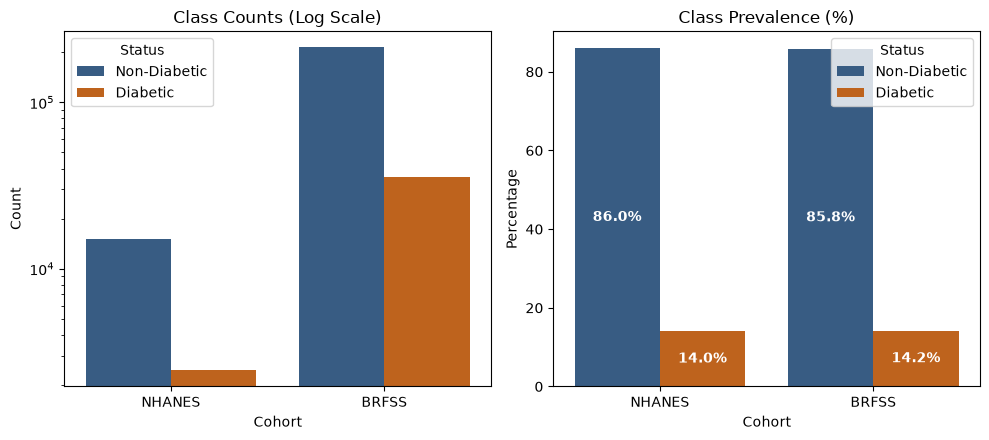

In [10]:
%matplotlib inline
import matplotlib.pyplot as plt, seaborn as sns, pandas as pd
df_nh = pd.read_csv('../../data/processed/nhanes_diabetes_processed.csv')
df_br = pd.read_csv('../../data/processed/brfss_diabetes_processed.csv')
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
df_cnt = pd.DataFrame({'Cohort': ['NHANES', 'NHANES', 'BRFSS', 'BRFSS'], 'Status': ['Non-Diabetic', 'Diabetic', 'Non-Diabetic', 'Diabetic'], 'Count': [(df_nh['diabetes']==0).sum(), (df_nh['diabetes']==1).sum(), (df_br['diabetes']==0).sum(), (df_br['diabetes']==1).sum()]})
sns.barplot(data=df_cnt, x='Cohort', y='Count', hue='Status', ax=axes[0], palette=['#2b5c8f', '#d95f02'])
axes[0].set_yscale('log'); axes[0].set_title('Class Counts (Log Scale)')
df_pct = pd.DataFrame({'Cohort': ['NHANES', 'NHANES', 'BRFSS', 'BRFSS'], 'Status': ['Non-Diabetic', 'Diabetic', 'Non-Diabetic', 'Diabetic'], 'Percentage': [(df_nh['diabetes']==0).mean()*100, (df_nh['diabetes']==1).mean()*100, (df_br['diabetes']==0).mean()*100, (df_br['diabetes']==1).mean()*100]})
sns.barplot(data=df_pct, x='Cohort', y='Percentage', hue='Status', ax=axes[1], palette=['#2b5c8f', '#d95f02'])
axes[1].set_title('Class Prevalence (%)')
for p in axes[1].patches:
    if p.get_height() > 0: axes[1].annotate(f"{p.get_height():.1f}%", (p.get_x()+p.get_width()/2., p.get_height()/2), ha='center', va='center', color='white', fontweight='bold')
plt.tight_layout()
fig.savefig('../reports/figures/final_a5_class_balance.png', dpi=300)
fig.savefig('../reports/paper/figures/final_a5_class_balance.png', dpi=300); fig.savefig('../reports/paper/figures/final_a5_class_balance.pdf')
plt.show()

# A6. Harmonized Feature Dictionary
Predictor mappings, survey sources, and harmonization.

In [11]:
import pandas as pd
a6_df = pd.DataFrame([
    {'Feature Name': 'age', 'Type': 'Continuous', 'NHANES Source': 'RIDAGEYR', 'BRFSS Equivalent': 'Age (13 buckets)', 'Coding / Range': '18.0 - 80.0 years', 'In Shared-7': 'Yes (Bucketized)'},
    {'Feature Name': 'sex', 'Type': 'Binary', 'NHANES Source': 'RIAGENDR', 'BRFSS Equivalent': 'Sex', 'Coding / Range': '1=Male, 0=Female', 'In Shared-7': 'Yes'},
    {'Feature Name': 'bmi', 'Type': 'Continuous', 'NHANES Source': 'BMXBMI', 'BRFSS Equivalent': 'BMI', 'Coding / Range': '12.0 - 67.3 kg/m2', 'In Shared-7': 'Yes'},
    {'Feature Name': 'mean_sbp', 'Type': 'Continuous', 'NHANES Source': 'BPXSY1-4', 'BRFSS Equivalent': 'Not available', 'Coding / Range': 'Systolic BP mean (mmHg)', 'In Shared-7': 'No'},
    {'Feature Name': 'mean_dbp', 'Type': 'Continuous', 'NHANES Source': 'BPXDI1-4', 'BRFSS Equivalent': 'Not available', 'Coding / Range': 'Diastolic BP mean (mmHg)', 'In Shared-7': 'No'},
    {'Feature Name': 'high_bp', 'Type': 'Binary', 'NHANES Source': 'BPQ020', 'BRFSS Equivalent': 'HighBP', 'Coding / Range': '1=Told high BP, 0=No', 'In Shared-7': 'Yes'},
    {'Feature Name': 'high_chol', 'Type': 'Binary', 'NHANES Source': 'BPQ080', 'BRFSS Equivalent': 'HighChol', 'Coding / Range': '1=Told high chol, 0=No', 'In Shared-7': 'Yes'},
    {'Feature Name': 'smoker', 'Type': 'Binary', 'NHANES Source': 'SMQ020', 'BRFSS Equivalent': 'Smoker', 'Coding / Range': '1=100+ cigarettes, 0=No', 'In Shared-7': 'Yes'},
    {'Feature Name': 'phys_activity', 'Type': 'Binary', 'NHANES Source': 'PAQ605/620/635/650/665', 'BRFSS Equivalent': 'PhysActivity', 'Coding / Range': '1=Active, 0=Inactive', 'In Shared-7': 'Yes'},
    {'Feature Name': 'family_history', 'Type': 'Binary', 'NHANES Source': 'MCQ300C', 'BRFSS Equivalent': 'Not available', 'Coding / Range': '1=Close relative diabetes, 0=No', 'In Shared-7': 'No'},
    {'Feature Name': 'hba1c (Tier 2)', 'Type': 'Continuous', 'NHANES Source': 'LBXGH', 'BRFSS Equivalent': 'Not available', 'Coding / Range': 'Glycated hemoglobin (%)', 'In Shared-7': 'No'}
])
a6_df.to_csv('../reports/paper/tables/feature_dictionary.csv', index=False)
display(a6_df.style.hide(axis='index'))

Feature Name,Type,NHANES Source,BRFSS Equivalent,Coding / Range,In Shared-7
age,Continuous,RIDAGEYR,Age (13 buckets),18.0 - 80.0 years,Yes (Bucketized)
sex,Binary,RIAGENDR,Sex,"1=Male, 0=Female",Yes
bmi,Continuous,BMXBMI,BMI,12.0 - 67.3 kg/m2,Yes
mean_sbp,Continuous,BPXSY1-4,Not available,Systolic BP mean (mmHg),No
mean_dbp,Continuous,BPXDI1-4,Not available,Diastolic BP mean (mmHg),No
high_bp,Binary,BPQ020,HighBP,"1=Told high BP, 0=No",Yes
high_chol,Binary,BPQ080,HighChol,"1=Told high chol, 0=No",Yes
smoker,Binary,SMQ020,Smoker,"1=100+ cigarettes, 0=No",Yes
phys_activity,Binary,PAQ605/620/635/650/665,PhysActivity,"1=Active, 0=Inactive",Yes
family_history,Binary,MCQ300C,Not available,"1=Close relative diabetes, 0=No",No


# A7. Missing Value Analysis
Imputation is fitted strictly on training data.

In [12]:
import pandas as pd
df_nh = pd.read_csv('../../data/processed/nhanes_diabetes_processed.csv')
df_t2 = pd.read_csv('../../data/processed/tier2_nhanes_with_hba1c.csv')
df_br = pd.read_csv('../../data/processed/brfss_diabetes_processed.csv')
t1_feats = ['age', 'bmi', 'mean_sbp', 'mean_dbp', 'high_bp', 'high_chol', 'smoker', 'phys_activity', 'family_history']
rows = [{'Cohort / Dataset': 'NHANES Tier 1 (n=17,468)', 'Feature': f, 'Missing Count': int(df_nh[f].isna().sum()), 'Missing (%)': f'{df_nh[f].isna().mean()*100:.2f}%', 'Handling': 'Median/Mode fit on train split'} for f in t1_feats]
rows.append({'Cohort / Dataset': 'NHANES Tier 2 Lab (n=17,468)', 'Feature': 'hba1c', 'Missing Count': int(df_t2['hba1c'].isna().sum()), 'Missing (%)': f'{df_t2["hba1c"].isna().mean()*100:.2f}%', 'Handling': 'Complete cases in Tier 2 evaluation'})
for f in ['age_bucket', 'sex', 'bmi', 'high_bp', 'high_chol', 'smoker', 'phys_activity']:
    rows.append({'Cohort / Dataset': 'BRFSS Shared (n=249,049)', 'Feature': f, 'Missing Count': int(df_br[f].isna().sum()), 'Missing (%)': f'{df_br[f].isna().mean()*100:.2f}%', 'Handling': 'Complete preprocessed dataset (0% missing)'})
a7_df = pd.DataFrame(rows)
a7_df.to_csv('../reports/paper/tables/missing_values.csv', index=False)
print("Note: Imputers fit strictly on the training split to prevent data leakage.")
display(a7_df.style.hide(axis='index'))

Note: Imputers fit strictly on the training split to prevent data leakage.


Cohort / Dataset,Feature,Missing Count,Missing (%),Handling
"NHANES Tier 1 (n=17,468)",age,0,0.00%,Median/Mode fit on train split
"NHANES Tier 1 (n=17,468)",bmi,993,5.68%,Median/Mode fit on train split
"NHANES Tier 1 (n=17,468)",mean_sbp,1385,7.93%,Median/Mode fit on train split
"NHANES Tier 1 (n=17,468)",mean_dbp,1385,7.93%,Median/Mode fit on train split
"NHANES Tier 1 (n=17,468)",high_bp,21,0.12%,Median/Mode fit on train split
"NHANES Tier 1 (n=17,468)",high_chol,106,0.61%,Median/Mode fit on train split
"NHANES Tier 1 (n=17,468)",smoker,11,0.06%,Median/Mode fit on train split
"NHANES Tier 1 (n=17,468)",phys_activity,0,0.00%,Median/Mode fit on train split
"NHANES Tier 1 (n=17,468)",family_history,1196,6.85%,Median/Mode fit on train split
"NHANES Tier 2 Lab (n=17,468)",hba1c,1532,8.77%,Complete cases in Tier 2 evaluation


# A8. Continuous Biomarkers by Class
Parametric and non-parametric continuous feature summaries.

In [13]:
import pandas as pd
df_nh = pd.read_csv('../../data/processed/nhanes_diabetes_processed.csv')
df_br = pd.read_csv('../../data/processed/brfss_diabetes_processed.csv')
rows = []
for c, name in [('age', 'Age (years)'), ('bmi', 'BMI (kg/m2)'), ('mean_sbp', 'Systolic BP (mmHg)'), ('mean_dbp', 'Diastolic BP (mmHg)')]:
    d = df_nh[df_nh['diabetes']==1][c].dropna(); nd = df_nh[df_nh['diabetes']==0][c].dropna()
    rows.append({'Dataset': 'NHANES', 'Feature': name, 'Diabetic Mean (SD)': f'{d.mean():.1f} ({d.std():.1f})', 'Diabetic Median [Min, Max]': f'{d.median():.1f} [{d.min():.1f}, {d.max():.1f}]', 'Non-Diabetic Mean (SD)': f'{nd.mean():.1f} ({nd.std():.1f})', 'Non-Diabetic Median [Min, Max]': f'{nd.median():.1f} [{nd.min():.1f}, {nd.max():.1f}]'})
d_b = df_br[df_br['diabetes']==1]['bmi'].dropna(); nd_b = df_br[df_br['diabetes']==0]['bmi'].dropna()
rows.append({'Dataset': 'BRFSS', 'Feature': 'BMI (kg/m2)', 'Diabetic Mean (SD)': f'{d_b.mean():.1f} ({d_b.std():.1f})', 'Diabetic Median [Min, Max]': f'{d_b.median():.1f} [{d_b.min():.1f}, {d_b.max():.1f}]', 'Non-Diabetic Mean (SD)': f'{nd_b.mean():.1f} ({nd_b.std():.1f})', 'Non-Diabetic Median [Min, Max]': f'{nd_b.median():.1f} [{nd_b.min():.1f}, {nd_b.max():.1f}]'})
a8_df = pd.DataFrame(rows)
a8_df.to_csv('../reports/paper/tables/numeric_summary.csv', index=False)
display(a8_df.style.hide(axis='index'))

Dataset,Feature,Diabetic Mean (SD),"Diabetic Median [Min, Max]",Non-Diabetic Mean (SD),"Non-Diabetic Median [Min, Max]"
NHANES,Age (years),62.1 (13.0),"63.0 [18.0, 80.0]",45.9 (18.4),"44.0 [18.0, 80.0]"
NHANES,BMI (kg/m2),32.4 (7.7),"31.1 [16.0, 84.4]",28.7 (7.0),"27.6 [14.1, 86.2]"
NHANES,Systolic BP (mmHg),132.6 (20.1),"129.3 [74.0, 238.0]",123.1 (18.2),"120.0 [64.7, 234.0]"
NHANES,Diastolic BP (mmHg),68.7 (14.2),"70.0 [0.0, 138.7]",70.4 (12.6),"70.7 [0.0, 135.3]"
BRFSS,BMI (kg/m2),31.9 (7.4),"31.0 [13.0, 98.0]",27.7 (6.3),"27.0 [12.0, 98.0]"


# A9. Categorical Risk Factor Breakdown
Prevalence and conditional diabetes rates across categories.

In [14]:
import pandas as pd
df_nh = pd.read_csv('../../data/processed/nhanes_diabetes_processed.csv')
cats = [('sex', 'Sex (Male=1, Female=0)'), ('high_bp', 'Told High Blood Pressure'), ('high_chol', 'Told High Cholesterol'), ('smoker', 'Cigarette Smoker'), ('phys_activity', 'Physical Activity'), ('family_history', 'Family History')]
rows = []
for c, name in cats:
    sub = df_nh.dropna(subset=[c])
    for val in sorted(sub[c].unique()):
        m = sub[sub[c]==val]; d = int(m['diabetes'].sum())
        rows.append({'Dataset': 'NHANES', 'Feature': name, 'Category': int(val), 'Count': len(m), 'Proportion': f'{len(m)/len(sub)*100:.1f}%', 'Diabetic Count': d, 'Diabetes Rate': f'{d/len(m)*100:.1f}%'})
a9_df = pd.DataFrame(rows)
a9_df.to_csv('../reports/paper/tables/categorical_breakdown.csv', index=False)
display(a9_df.style.hide(axis='index'))

Dataset,Feature,Category,Count,Proportion,Diabetic Count,Diabetes Rate
NHANES,"Sex (Male=1, Female=0)",0,9060,51.9%,1164,12.8%
NHANES,"Sex (Male=1, Female=0)",1,8408,48.1%,1285,15.3%
NHANES,Told High Blood Pressure,0,11362,65.1%,748,6.6%
NHANES,Told High Blood Pressure,1,6085,34.9%,1694,27.8%
NHANES,Told High Cholesterol,0,11720,67.5%,914,7.8%
NHANES,Told High Cholesterol,1,5642,32.5%,1492,26.4%
NHANES,Cigarette Smoker,0,10310,59.1%,1246,12.1%
NHANES,Cigarette Smoker,1,7147,40.9%,1202,16.8%
NHANES,Physical Activity,0,4548,26.0%,951,20.9%
NHANES,Physical Activity,1,12920,74.0%,1498,11.6%


# A10. Age Distribution by Class
Age histograms and bucketed distributions across cohorts.

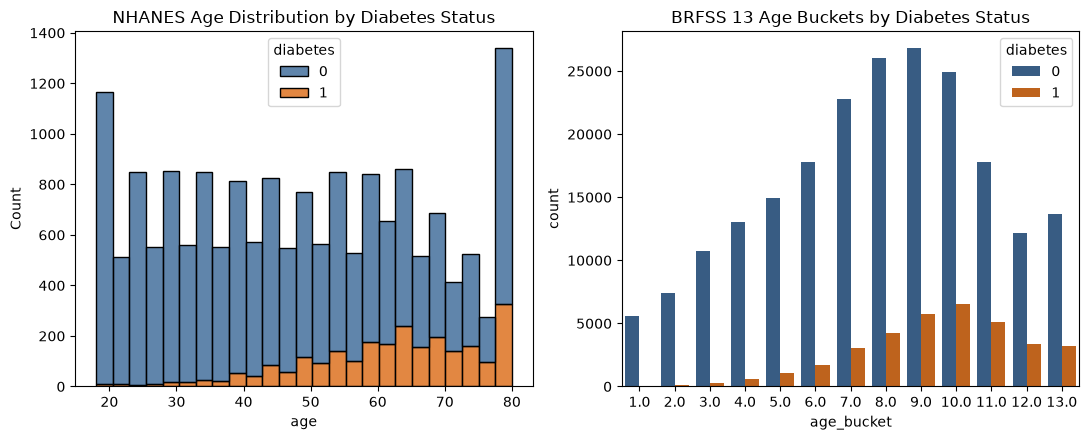

In [15]:
%matplotlib inline
import matplotlib.pyplot as plt, seaborn as sns, pandas as pd
df_nh = pd.read_csv('../../data/processed/nhanes_diabetes_processed.csv')
df_br = pd.read_csv('../../data/processed/brfss_diabetes_processed.csv')
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.histplot(data=df_nh, x='age', hue='diabetes', multiple='stack', bins=25, ax=axes[0], palette=['#2b5c8f', '#d95f02'])
axes[0].set_title('NHANES Age Distribution by Diabetes Status')
sns.countplot(data=df_br, x='age_bucket', hue='diabetes', ax=axes[1], palette=['#2b5c8f', '#d95f02'])
axes[1].set_title('BRFSS 13 Age Buckets by Diabetes Status')
plt.tight_layout()
fig.savefig('../reports/figures/final_a10_age_distribution.png', dpi=300)
fig.savefig('../reports/paper/figures/final_a10_age_distribution.png', dpi=300); fig.savefig('../reports/paper/figures/final_a10_age_distribution.pdf')
plt.show()

# A11. Data Partitioning and Splits
Leakage-free partitions; test and BRFSS held out untouched.

In [16]:
import json, pandas as pd
with open('../models/split_indices.json') as f: splits = json.load(f)
df1 = pd.read_csv('../../data/processed/nhanes_diabetes_processed.csv')
df2 = pd.read_csv('../../data/processed/tier2_nhanes_with_hba1c.csv').dropna(subset=['hba1c'])
rows = []
for tier, df, prefix in [('Tier 1 (No Labs)', df1, 'Tier 1'), ('Tier 2 (With HbA1c)', df2, 'Tier 2')]:
    for split_name, idx_key in [('Train Split (70%)', 'train_indices'), ('Validation Split (15%)', 'val_indices'), ('Test Split (15%)', 'test_indices')]:
        sub = df.loc[df.index.intersection(splits[idx_key])]
        d = int(sub['diabetes'].sum())
        rows.append({'Tier': tier, 'Split': split_name, 'Total Rows': len(sub), 'Diabetic': d, 'Non-Diabetic': len(sub)-d, 'Prevalence': f'{d/len(sub)*100:.2f}%'})
a11_df = pd.DataFrame(rows)
a11_df.to_csv('../reports/paper/tables/splits_summary.csv', index=False)
print("One line: split first, preprocessing fit on train only, thresholds chosen on validation only, test and BRFSS never used for tuning.")
display(a11_df.style.hide(axis='index'))

One line: split first, preprocessing fit on train only, thresholds chosen on validation only, test and BRFSS never used for tuning.


Tier,Split,Total Rows,Diabetic,Non-Diabetic,Prevalence
Tier 1 (No Labs),Train Split (70%),12227,1714,10513,14.02%
Tier 1 (No Labs),Validation Split (15%),2620,367,2253,14.01%
Tier 1 (No Labs),Test Split (15%),2621,368,2253,14.04%
Tier 2 (With HbA1c),Train Split (70%),11153,1589,9564,14.25%
Tier 2 (With HbA1c),Validation Split (15%),2391,347,2044,14.51%
Tier 2 (With HbA1c),Test Split (15%),2392,342,2050,14.30%


# A12. Glycated Hemoglobin Distribution and Crosstab
Empirical distribution of HbA1c against self-reported labels.

Plain statement: HbA1c distributions show strong observational separation across diagnosis classes; no causal relationship inferred.


HbA1c Category,Non-Diabetic (0),Diabetic (1),All,Diabetes Rate
Normal (<5.7%),9522,158,9680,1.63%
Prediabetic (5.7-6.4%),3744,570,4314,13.21%
Diabetic (>=6.5%),392,1550,1942,79.81%
All,13658,2278,15936,14.29%


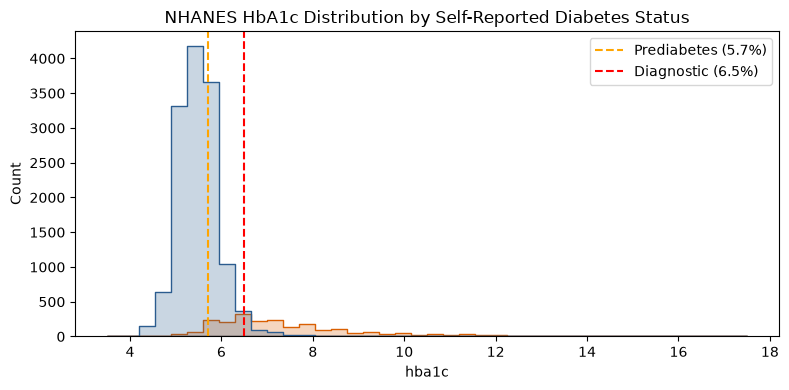

In [17]:
%matplotlib inline
import matplotlib.pyplot as plt, seaborn as sns, pandas as pd
df2 = pd.read_csv('../../data/processed/tier2_nhanes_with_hba1c.csv').dropna(subset=['hba1c'])
df2['cat'] = pd.cut(df2['hba1c'], bins=[0, 5.699, 6.499, 30.0], labels=['Normal (<5.7%)', 'Prediabetic (5.7-6.4%)', 'Diabetic (>=6.5%)'])
ct = pd.crosstab(df2['cat'], df2['diabetes'], margins=True).reset_index().rename(columns={'cat': 'HbA1c Category', 0: 'Non-Diabetic (0)', 1: 'Diabetic (1)'})
ct['Diabetes Rate'] = (ct['Diabetic (1)'] / ct['All'] * 100).round(2).astype(str) + '%'
ct.to_csv('../reports/paper/tables/hba1c_crosstab.csv', index=False)
print("Plain statement: HbA1c distributions show strong observational separation across diagnosis classes; no causal relationship inferred.")
display(ct.style.hide(axis='index'))
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=df2, x='hba1c', hue='diabetes', bins=40, element='step', ax=ax, palette=['#2b5c8f', '#d95f02'])
ax.axvline(5.7, color='orange', linestyle='--', label='Prediabetes (5.7%)'); ax.axvline(6.5, color='red', linestyle='--', label='Diagnostic (6.5%)')
ax.legend(); ax.set_title('NHANES HbA1c Distribution by Self-Reported Diabetes Status'); plt.tight_layout()
fig.savefig('../reports/figures/final_a12_hba1c_distribution.png', dpi=300)
fig.savefig('../reports/paper/figures/final_a12_hba1c_distribution.png', dpi=300); fig.savefig('../reports/paper/figures/final_a12_hba1c_distribution.pdf')
plt.show()

# A13. Modeling Framework Overview
Summary of the five core model architectures.

In [18]:
import pandas as pd
a13_df = pd.DataFrame([
    {'Model Name': 'Logistic Regression', 'Category': 'Classical ML', 'Tier 1 Features': '10 tabular features (Standardized & Imputed)', 'Tier 2 Features': '11 features (10 tabular + HbA1c)'},
    {'Model Name': 'Random Forest', 'Category': 'Classical ML', 'Tier 1 Features': '10 tabular features', 'Tier 2 Features': '11 features'},
    {'Model Name': 'XGBoost', 'Category': 'Classical ML (Boosted)', 'Tier 1 Features': '10 tabular features', 'Tier 2 Features': '11 features'},
    {'Model Name': 'PyTorch MLP', 'Category': 'Deep Learning', 'Tier 1 Features': '10 tabular features', 'Tier 2 Features': '11 features'},
    {'Model Name': 'Stacking Ensemble', 'Category': 'Hybrid Ensemble', 'Tier 1 Features': 'Meta-learner over LR, RF, XGB, MLP', 'Tier 2 Features': 'Meta-learner over Tier 2 LR, RF, XGB, MLP'}
])
a13_df.to_csv('../reports/paper/tables/models_summary.csv', index=False)
display(a13_df.style.hide(axis='index'))

Model Name,Category,Tier 1 Features,Tier 2 Features
Logistic Regression,Classical ML,10 tabular features (Standardized & Imputed),11 features (10 tabular + HbA1c)
Random Forest,Classical ML,10 tabular features,11 features
XGBoost,Classical ML (Boosted),10 tabular features,11 features
PyTorch MLP,Deep Learning,10 tabular features,11 features
Stacking Ensemble,Hybrid Ensemble,"Meta-learner over LR, RF, XGB, MLP","Meta-learner over Tier 2 LR, RF, XGB, MLP"


# B1. Tier 1 Test Set Performance
Evaluated at validation-selected 80% recall operating points.

In [19]:
import numpy as np, pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
p1 = pd.read_csv('../reports/predictions/nhanes_full_test_probabilities.csv')
y1 = p1['y_true'].values
ths1 = {'Logistic Regression': (0.473, 'prob_logreg'), 'Random Forest': (0.352, 'prob_rf'), 'XGBoost': (0.499, 'prob_xgboost'), 'MLP (Deep Learning)': (0.527, 'prob_mlp'), 'Stacking Ensemble (Hybrid)': (0.138, 'prob_stacking')}
rows1 = [{'Model': m, 'Accuracy': round(accuracy_score(y1, (p1[col].values>=th).astype(int)), 3), 'Precision': round(precision_score(y1, (p1[col].values>=th).astype(int)), 3), 'Recall': round(recall_score(y1, (p1[col].values>=th).astype(int)), 3), 'F1': round(f1_score(y1, (p1[col].values>=th).astype(int)), 3), 'ROC-AUC': round(roc_auc_score(y1, p1[col].values), 3)} for m, (th, col) in ths1.items()]
b1_df = pd.DataFrame(rows1)
b1_df.to_csv('../reports/paper/tables/tier1_test_models.csv', index=False)
cols = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']
display(b1_df.style.format({c: '{:.3f}' for c in cols}).highlight_max(subset=cols, color='#d1e7dd').hide(axis='index'))

Model,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.741,0.332,0.840,0.476,0.858
Random Forest,0.743,0.333,0.829,0.475,0.853
XGBoost,0.762,0.351,0.826,0.493,0.858
MLP (Deep Learning),0.757,0.349,0.848,0.495,0.857
Stacking Ensemble (Hybrid),0.754,0.344,0.826,0.485,0.861


# B2. Tier 1 Confusion Matrices
Tier 1 confusion matrices with thresholds printed underneath.

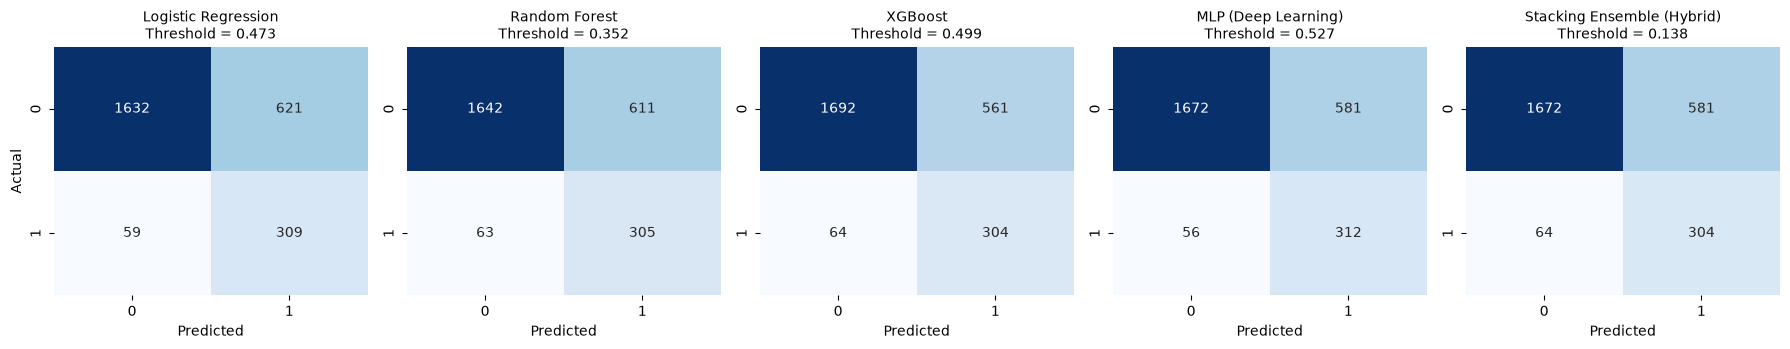

In [20]:
%matplotlib inline
import matplotlib.pyplot as plt, seaborn as sns, pandas as pd
from sklearn.metrics import confusion_matrix
p1 = pd.read_csv('../reports/predictions/nhanes_full_test_probabilities.csv')
y1 = p1['y_true'].values
ths1 = {'Logistic Regression': (0.473, 'prob_logreg'), 'Random Forest': (0.352, 'prob_rf'), 'XGBoost': (0.499, 'prob_xgboost'), 'MLP (Deep Learning)': (0.527, 'prob_mlp'), 'Stacking Ensemble (Hybrid)': (0.138, 'prob_stacking')}
fig, axes = plt.subplots(1, 5, figsize=(18, 3.6))
for idx, (m_name, (th, col)) in enumerate(ths1.items()):
    cm = confusion_matrix(y1, (p1[col].values >= th).astype(int))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[idx])
    axes[idx].set_title(f"{m_name}\nThreshold = {th:.3f}", fontsize=10)
    axes[idx].set_xlabel('Predicted'); axes[idx].set_ylabel('Actual' if idx==0 else '')
plt.tight_layout()
fig.savefig('../reports/figures/final_b2_confusion_matrices.png', dpi=300)
fig.savefig('../reports/paper/figures/final_b2_confusion_matrices.png', dpi=300); fig.savefig('../reports/paper/figures/final_b2_confusion_matrices.pdf')
plt.show()

# B3. Tier 1 ROC Curves
Receiver Operating Characteristic curves for Tier 1 models.

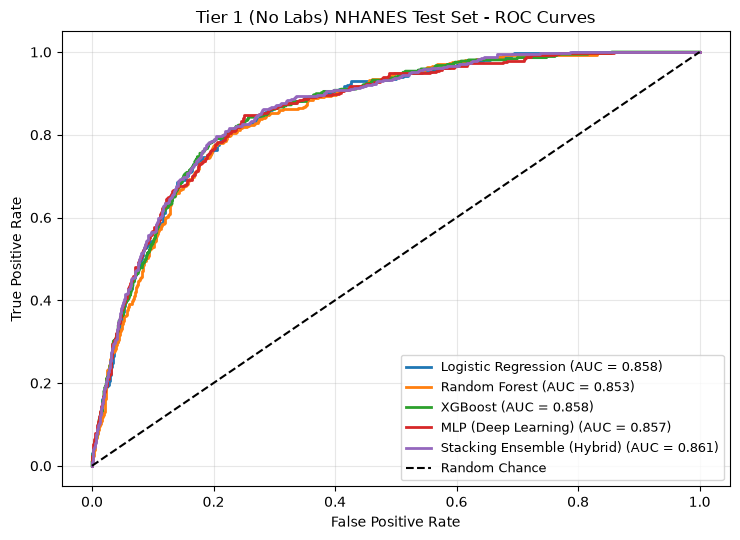

In [21]:
%matplotlib inline
import matplotlib.pyplot as plt, pandas as pd
from sklearn.metrics import roc_curve, roc_auc_score
p1 = pd.read_csv('../reports/predictions/nhanes_full_test_probabilities.csv')
y1 = p1['y_true'].values
ths1 = {'Logistic Regression': 'prob_logreg', 'Random Forest': 'prob_rf', 'XGBoost': 'prob_xgboost', 'MLP (Deep Learning)': 'prob_mlp', 'Stacking Ensemble (Hybrid)': 'prob_stacking'}
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for m_name, col in ths1.items():
    fpr, tpr, _ = roc_curve(y1, p1[col].values)
    ax.plot(fpr, tpr, lw=2, label=f"{m_name} (AUC = {roc_auc_score(y1, p1[col].values):.3f})")
ax.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Chance')
ax.set_title('Tier 1 (No Labs) NHANES Test Set - ROC Curves')
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.legend(loc='lower right', fontsize=9); ax.grid(True, alpha=0.3); plt.tight_layout()
fig.savefig('../reports/figures/final_b3_roc_curves.png', dpi=300)
fig.savefig('../reports/paper/figures/final_b3_roc_curves.png', dpi=300); fig.savefig('../reports/paper/figures/final_b3_roc_curves.pdf')
plt.show()

# B4. Tier 1 Dual Operating Points
High-Accuracy vs Screening mode for Final Calibrated XGBoost.

In [22]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
p1 = pd.read_csv('../reports/predictions/nhanes_full_test_probabilities.csv')
y1, prob_cal = p1['y_true'].values, p1['prob_final_calibrated_xgb'].values
rows = []
for mode, th in [('High-Accuracy Mode (Standard)', 0.402), ('Screening Mode (80% Recall)', 0.144)]:
    pred = (prob_cal >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y1, pred).ravel()
    rows.append({'Mode': mode, 'Threshold': th, 'Accuracy': round(accuracy_score(y1, pred), 3), 'Precision': round(precision_score(y1, pred), 3), 'Recall': round(recall_score(y1, pred), 3), 'Specificity': round(tn/(tn+fp), 3), 'F1': round(f1_score(y1, pred), 3)})
b4_df = pd.DataFrame(rows)
b4_df.to_csv('../reports/paper/tables/tier1_dual_mode.csv', index=False)
display(b4_df.style.hide(axis='index'))

Mode,Threshold,Accuracy,Precision,Recall,Specificity,F1
High-Accuracy Mode (Standard),0.402000,0.869000,0.568000,0.272000,0.966000,0.368000
Screening Mode (80% Recall),0.144000,0.763000,0.353000,0.823000,0.753000,0.494000


# B5. BRFSS External Validation
Zero-shot evaluation using validation-selected thresholds.

In [23]:
import pandas as pd
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score
pb = pd.read_csv('../reports/predictions/brfss_probabilities.csv')
yb = pb['y_true'].values
ths_b = {'Logistic Regression': (0.473, 'prob_logreg'), 'Random Forest': (0.352, 'prob_rf'), 'XGBoost': (0.499, 'prob_xgboost'), 'PyTorch MLP': (0.527, 'prob_mlp'), 'Stacking Ensemble': (0.138, 'prob_stacking')}
rows_b = [{'Model': m, 'NHANES Validation Threshold': th, 'Accuracy': round(accuracy_score(yb, (pb[col].values>=th).astype(int)), 3), 'Recall': round(recall_score(yb, (pb[col].values>=th).astype(int)), 3), 'ROC-AUC': round(roc_auc_score(yb, pb[col].values), 3)} for m, (th, col) in ths_b.items()]
b5_df = pd.DataFrame(rows_b)
b5_df.to_csv('../reports/paper/tables/brfss_external_validation.csv', index=False)
cols = ['Accuracy', 'Recall', 'ROC-AUC']
display(b5_df.style.format({c: '{:.3f}' for c in cols}).highlight_max(subset=cols, color='#d1e7dd').hide(axis='index'))

Model,NHANES Validation Threshold,Accuracy,Recall,ROC-AUC
Logistic Regression,0.473000,0.607,0.855,0.784
Random Forest,0.352000,0.509,0.919,0.784
XGBoost,0.499000,0.599,0.862,0.790
PyTorch MLP,0.527000,0.605,0.863,0.792
Stacking Ensemble,0.138000,0.610,0.859,0.792


# C1. Tier 2 Test Set Performance
Evaluated at validation-selected 80% recall operating points.

In [24]:
import json, numpy as np, pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
p2 = pd.read_csv('../reports/predictions/tier2_test_probabilities.csv')
y2 = p2['y_true'].values
df2 = pd.read_csv('../../data/processed/tier2_nhanes_with_hba1c.csv')
with open('../models/split_indices.json') as f: splits = json.load(f)
hba1c_te = df2.iloc[splits['test_indices']].dropna(subset=['hba1c'])['hba1c'].values
pred_hba1c = (hba1c_te >= 6.5).astype(int)
tn_r, fp_r, fn_r, tp_r = confusion_matrix(y2, pred_hba1c).ravel()
rows2 = [
    {'Model': 'Baseline: Predict everyone healthy', 'Accuracy': round(accuracy_score(y2, np.zeros_like(y2)), 3), 'Precision': 0.0, 'Recall': 0.0, 'F1': 0.0, 'ROC-AUC': 0.500},
    {'Model': 'Baseline: HbA1c >= 6.5% rule', 'Accuracy': round(accuracy_score(y2, pred_hba1c), 3), 'Precision': round(precision_score(y2, pred_hba1c), 3), 'Recall': round(recall_score(y2, pred_hba1c), 3), 'F1': round(f1_score(y2, pred_hba1c), 3), 'ROC-AUC': round((recall_score(y2, pred_hba1c) + tn_r/(tn_r+fp_r))/2, 3)}
]
ths2 = {'Logistic Regression': (0.575, 'prob_logreg'), 'Random Forest': (0.546, 'prob_rf'), 'XGBoost': (0.599, 'prob_xgboost'), 'MLP (Deep Learning)': (0.636, 'prob_mlp'), 'Stacking Ensemble (Hybrid)': (0.233, 'prob_stacking')}
for m, (th, col) in ths2.items():
    pred = (p2[col].values >= th).astype(int)
    rows2.append({'Model': m, 'Accuracy': round(accuracy_score(y2, pred), 3), 'Precision': round(precision_score(y2, pred), 3), 'Recall': round(recall_score(y2, pred), 3), 'F1': round(f1_score(y2, pred), 3), 'ROC-AUC': round(roc_auc_score(y2, p2[col].values), 3)})
c1_df = pd.DataFrame(rows2)
c1_df.to_csv('../reports/paper/tables/tier2_test_models.csv', index=False)
cols = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']
display(c1_df.style.format({c: '{:.3f}' for c in cols}).highlight_max(subset=cols, color='#d1e7dd').hide(axis='index'))

Model,Accuracy,Precision,Recall,F1,ROC-AUC
Baseline: Predict everyone healthy,0.857,0.000,0.000,0.000,0.500
Baseline: HbA1c >= 6.5% rule,0.932,0.806,0.693,0.745,0.833
Logistic Regression,0.910,0.638,0.851,0.729,0.944
Random Forest,0.918,0.671,0.833,0.743,0.949
XGBoost,0.923,0.692,0.827,0.754,0.949
MLP (Deep Learning),0.921,0.679,0.842,0.752,0.950
Stacking Ensemble (Hybrid),0.917,0.666,0.839,0.743,0.951


# C2. Tier 2 Confusion Matrices
Tier 2 confusion matrices with thresholds printed underneath.

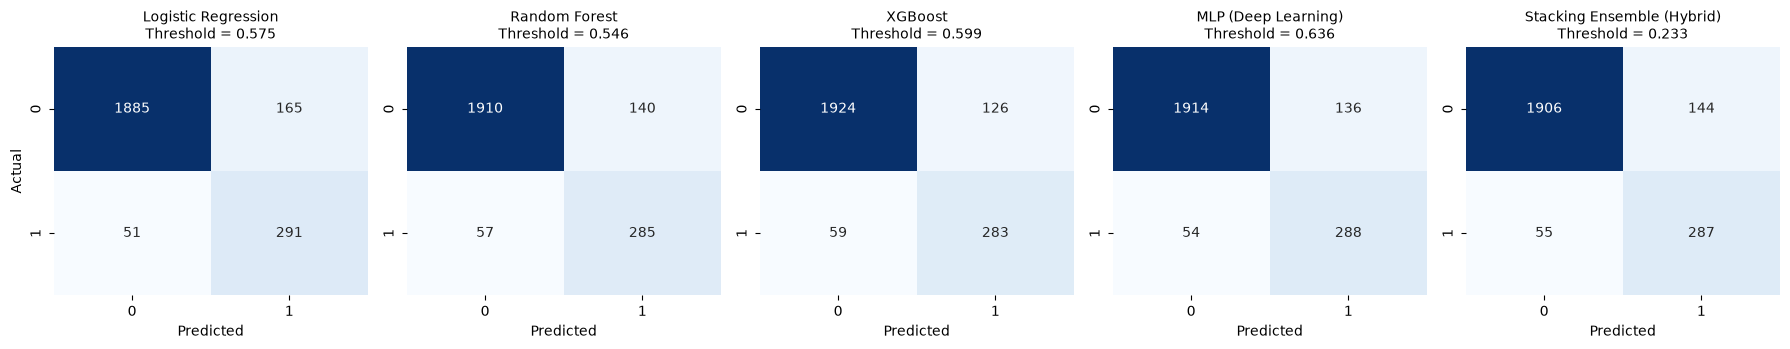

In [25]:
%matplotlib inline
import matplotlib.pyplot as plt, seaborn as sns, pandas as pd
from sklearn.metrics import confusion_matrix
p2 = pd.read_csv('../reports/predictions/tier2_test_probabilities.csv')
y2 = p2['y_true'].values
ths2 = {'Logistic Regression': (0.575, 'prob_logreg'), 'Random Forest': (0.546, 'prob_rf'), 'XGBoost': (0.599, 'prob_xgboost'), 'MLP (Deep Learning)': (0.636, 'prob_mlp'), 'Stacking Ensemble (Hybrid)': (0.233, 'prob_stacking')}
fig, axes = plt.subplots(1, 5, figsize=(18, 3.6))
for idx, (m_name, (th, col)) in enumerate(ths2.items()):
    cm = confusion_matrix(y2, (p2[col].values >= th).astype(int))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[idx])
    axes[idx].set_title(f"{m_name}\nThreshold = {th:.3f}", fontsize=10)
    axes[idx].set_xlabel('Predicted'); axes[idx].set_ylabel('Actual' if idx==0 else '')
plt.tight_layout()
fig.savefig('../reports/figures/final_c2_tier2_confusion_matrices.png', dpi=300)
fig.savefig('../reports/paper/figures/final_c2_tier2_confusion_matrices.png', dpi=300); fig.savefig('../reports/paper/figures/final_c2_tier2_confusion_matrices.pdf')
plt.show()

# C3. Tier 2 ROC Curves
ROC curves compared against clinical diagnostic threshold.

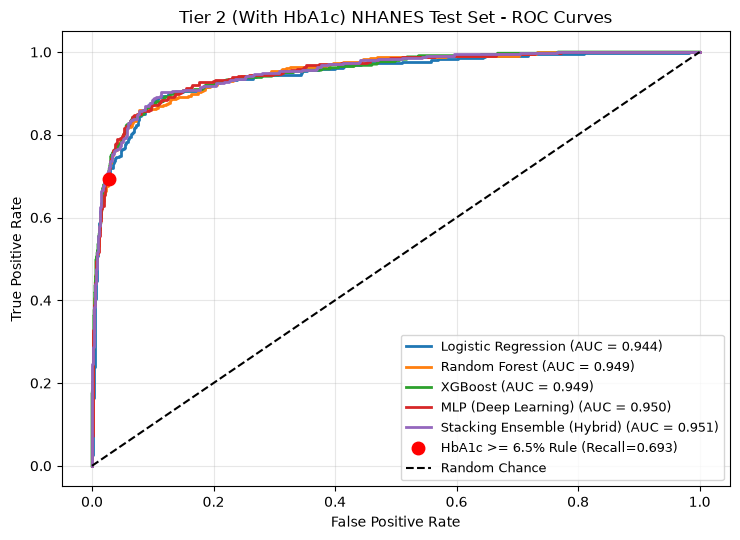

In [26]:
%matplotlib inline
import json, matplotlib.pyplot as plt, pandas as pd
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix
p2 = pd.read_csv('../reports/predictions/tier2_test_probabilities.csv')
y2 = p2['y_true'].values
df2 = pd.read_csv('../../data/processed/tier2_nhanes_with_hba1c.csv')
with open('../models/split_indices.json') as f: splits = json.load(f)
hba1c_te = df2.iloc[splits['test_indices']].dropna(subset=['hba1c'])['hba1c'].values
pred_r = (hba1c_te >= 6.5).astype(int)
tn_r, fp_r, fn_r, tp_r = confusion_matrix(y2, pred_r).ravel()
fig, ax = plt.subplots(figsize=(7.5, 5.5))
ths2 = {'Logistic Regression': 'prob_logreg', 'Random Forest': 'prob_rf', 'XGBoost': 'prob_xgboost', 'MLP (Deep Learning)': 'prob_mlp', 'Stacking Ensemble (Hybrid)': 'prob_stacking'}
for m_name, col in ths2.items():
    fpr, tpr, _ = roc_curve(y2, p2[col].values)
    ax.plot(fpr, tpr, lw=2, label=f"{m_name} (AUC = {roc_auc_score(y2, p2[col].values):.3f})")
ax.plot(fp_r/(tn_r+fp_r), tp_r/(tp_r+fn_r), 'ro', markersize=9, label=f"HbA1c >= 6.5% Rule (Recall={tp_r/(tp_r+fn_r):.3f})")
ax.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Chance')
ax.set_title('Tier 2 (With HbA1c) NHANES Test Set - ROC Curves')
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.legend(loc='lower right', fontsize=9); ax.grid(True, alpha=0.3); plt.tight_layout()
fig.savefig('../reports/figures/final_c3_tier2_roc_curves.png', dpi=300)
fig.savefig('../reports/paper/figures/final_c3_tier2_roc_curves.png', dpi=300); fig.savefig('../reports/paper/figures/final_c3_tier2_roc_curves.pdf')
plt.show()

# C4. Tier 2 Dual Operating Points
High-Accuracy vs Screening mode for Tier 2 Calibrated XGBoost.

In [27]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
p2 = pd.read_csv('../reports/predictions/tier2_test_probabilities.csv')
y2, prob_cal2 = p2['y_true'].values, p2['prob_final_calibrated_xgb'].values
rows = []
for mode, th in [('High-Accuracy Mode (Standard)', 0.376), ('Screening Mode (80% Recall)', 0.290)]:
    pred = (prob_cal2 >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y2, pred).ravel()
    rows.append({'Mode': mode, 'Threshold': th, 'Accuracy': round(accuracy_score(y2, pred), 3), 'Precision': round(precision_score(y2, pred), 3), 'Recall': round(recall_score(y2, pred), 3), 'Specificity': round(tn/(tn+fp), 3), 'F1': round(f1_score(y2, pred), 3)})
c4_df = pd.DataFrame(rows)
c4_df.to_csv('../reports/paper/tables/tier2_dual_mode.csv', index=False)
display(c4_df.style.hide(axis='index'))

Mode,Threshold,Accuracy,Precision,Recall,Specificity,F1
High-Accuracy Mode (Standard),0.376000,0.935000,0.805000,0.722000,0.971000,0.761000
Screening Mode (80% Recall),0.290000,0.923000,0.692000,0.827000,0.939000,0.754000


# D1. Tier 1 Versus Tier 2 Comparison
Evaluated on identical test participants with laboratory HbA1c.

Metric,Tier 1,Tier 2,Delta
ROC-AUC,0.852000,0.946000,0.094000
Accuracy (High-Acc),0.865000,0.935000,0.070000
Recall (High-Acc),0.272000,0.722000,0.450000
Accuracy (Screening),0.758000,0.923000,0.164000
Recall (Screening),0.825000,0.827000,0.003000


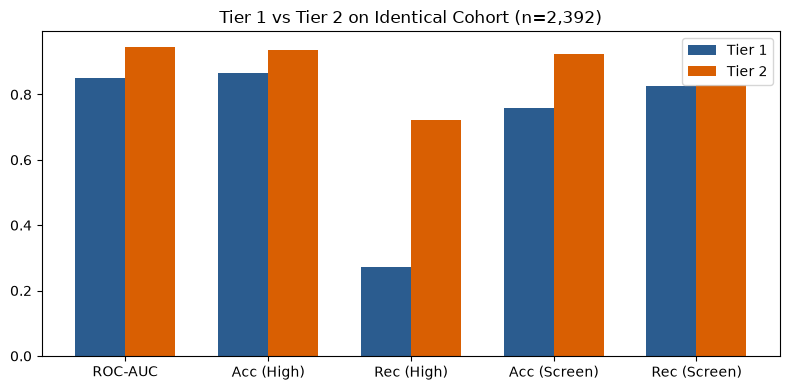

In [28]:
%matplotlib inline
import json, matplotlib.pyplot as plt, numpy as np, pandas as pd
from sklearn.metrics import roc_auc_score, accuracy_score, recall_score
p1 = pd.read_csv('../reports/predictions/nhanes_full_test_probabilities.csv')
p2 = pd.read_csv('../reports/predictions/tier2_test_probabilities.csv')
df2 = pd.read_csv('../../data/processed/tier2_nhanes_with_hba1c.csv')
with open('../models/split_indices.json') as f: splits = json.load(f)
mask = df2.iloc[splits['test_indices']]['hba1c'].notna().values
y_id = p1['y_true'].values[mask]
p1_cal_id = p1['prob_final_calibrated_xgb'].values[mask]
p2_cal = p2['prob_final_calibrated_xgb'].values
auc1, auc2 = roc_auc_score(y_id, p1_cal_id), roc_auc_score(y_id, p2_cal)
acc1_a, acc2_a = accuracy_score(y_id, (p1_cal_id>=0.402).astype(int)), accuracy_score(y_id, (p2_cal>=0.376).astype(int))
rec1_a, rec2_a = recall_score(y_id, (p1_cal_id>=0.402).astype(int)), recall_score(y_id, (p2_cal>=0.376).astype(int))
acc1_s, acc2_s = accuracy_score(y_id, (p1_cal_id>=0.144).astype(int)), accuracy_score(y_id, (p2_cal>=0.290).astype(int))
rec1_s, rec2_s = recall_score(y_id, (p1_cal_id>=0.144).astype(int)), recall_score(y_id, (p2_cal>=0.290).astype(int))
d1_df = pd.DataFrame([
    {'Metric': 'ROC-AUC', 'Tier 1': round(auc1, 3), 'Tier 2': round(auc2, 3), 'Delta': round(auc2-auc1, 3)},
    {'Metric': 'Accuracy (High-Acc)', 'Tier 1': round(acc1_a, 3), 'Tier 2': round(acc2_a, 3), 'Delta': round(acc2_a-acc1_a, 3)},
    {'Metric': 'Recall (High-Acc)', 'Tier 1': round(rec1_a, 3), 'Tier 2': round(rec2_a, 3), 'Delta': round(rec2_a-rec1_a, 3)},
    {'Metric': 'Accuracy (Screening)', 'Tier 1': round(acc1_s, 3), 'Tier 2': round(acc2_s, 3), 'Delta': round(acc2_s-acc1_s, 3)},
    {'Metric': 'Recall (Screening)', 'Tier 1': round(rec1_s, 3), 'Tier 2': round(rec2_s, 3), 'Delta': round(rec2_s-rec1_s, 3)}
])
d1_df.to_csv('../reports/paper/tables/tier1_vs_tier2_comparison.csv', index=False)
display(d1_df.style.hide(axis='index'))
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(5); w = 0.35
ax.bar(x-w/2, [auc1, acc1_a, rec1_a, acc1_s, rec1_s], w, label='Tier 1', color='#2b5c8f')
ax.bar(x+w/2, [auc2, acc2_a, rec2_a, acc2_s, rec2_s], w, label='Tier 2', color='#d95f02')
ax.set_xticks(x); ax.set_xticklabels(['ROC-AUC', 'Acc (High)', 'Rec (High)', 'Acc (Screen)', 'Rec (Screen)'])
ax.legend(); ax.set_title('Tier 1 vs Tier 2 on Identical Cohort (n=2,392)'); plt.tight_layout()
fig.savefig('../reports/figures/final_d1_tier1_vs_tier2.png', dpi=300)
fig.savefig('../reports/paper/figures/final_d1_tier1_vs_tier2.png', dpi=300); fig.savefig('../reports/paper/figures/final_d1_tier1_vs_tier2.pdf')
plt.show()

# D2. Tier 1 SHAP Feature Importance
Tree SHAP feature importance for non-invasive screening.

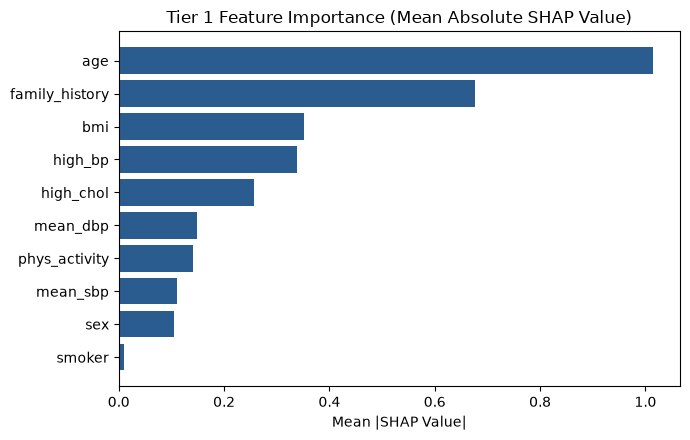

In [29]:
import json, joblib, matplotlib.pyplot as plt, numpy as np, pandas as pd, xgboost as xgb
import sys; sys.path.insert(0, '../src')
import train_and_evaluate; import __main__; __main__.TabularPreprocessor = train_and_evaluate.TabularPreprocessor
%matplotlib inline
df1 = pd.read_csv('../../data/processed/nhanes_diabetes_processed.csv')
with open('../models/split_indices.json') as f: splits = json.load(f)
prep1 = joblib.load('../models/preprocessor_full.joblib')
m_xgb1 = joblib.load('../models/xgb_full.joblib')
X1_test = prep1.transform(df1.iloc[splits['test_indices']])
contribs1 = m_xgb1.get_booster().predict(xgb.DMatrix(X1_test, feature_names=prep1.all_cols), pred_contribs=True)[:, :-1]
mean_shap1 = np.abs(contribs1).mean(axis=0)
d2_df = pd.DataFrame({'Feature': prep1.all_cols, 'Mean |SHAP|': mean_shap1}).sort_values('Mean |SHAP|', ascending=True)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(d2_df['Feature'], d2_df['Mean |SHAP|'], color='#2b5c8f')
ax.set_title('Tier 1 Feature Importance (Mean Absolute SHAP Value)'); ax.set_xlabel('Mean |SHAP Value|'); plt.tight_layout()
fig.savefig('../reports/figures/final_d2_shap_tier1.png', dpi=300)
fig.savefig('../reports/paper/figures/final_d2_shap_tier1.png', dpi=300); fig.savefig('../reports/paper/figures/final_d2_shap_tier1.pdf')
plt.show()

# D3. Tier 2 SHAP Feature Importance
Tree SHAP feature importance incorporating laboratory HbA1c.

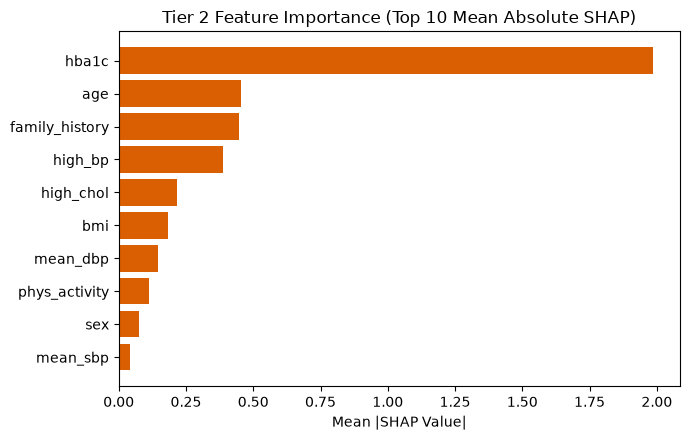

In [30]:
import json, joblib, matplotlib.pyplot as plt, numpy as np, pandas as pd, xgboost as xgb
import sys; sys.path.insert(0, '../src')
import train_and_evaluate; import __main__; __main__.TabularPreprocessor = train_and_evaluate.TabularPreprocessor
%matplotlib inline
df2 = pd.read_csv('../../data/processed/tier2_nhanes_with_hba1c.csv')
with open('../models/split_indices.json') as f: splits = json.load(f)
prep2 = joblib.load('../models/tier2_preprocessor.joblib')
m_xgb2 = joblib.load('../models/tier2_xgb.joblib')
t2_sub = df2.iloc[splits['test_indices']].dropna(subset=['hba1c'])
all_cols_t2 = ['age', 'bmi', 'mean_sbp', 'mean_dbp', 'hba1c', 'sex', 'high_bp', 'high_chol', 'smoker', 'phys_activity', 'family_history']
X2_test = prep2.transform(t2_sub[all_cols_t2])
contribs2 = m_xgb2.get_booster().predict(xgb.DMatrix(X2_test, feature_names=all_cols_t2), pred_contribs=True)[:, :-1]
mean_shap2 = np.abs(contribs2).mean(axis=0)
d3_df = pd.DataFrame({'Feature': all_cols_t2, 'Mean |SHAP|': mean_shap2}).sort_values('Mean |SHAP|', ascending=False).head(10).sort_values('Mean |SHAP|', ascending=True)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(d3_df['Feature'], d3_df['Mean |SHAP|'], color='#d95f02')
ax.set_title('Tier 2 Feature Importance (Top 10 Mean Absolute SHAP)'); ax.set_xlabel('Mean |SHAP Value|'); plt.tight_layout()
fig.savefig('../reports/figures/final_d3_shap_tier2.png', dpi=300)
fig.savefig('../reports/paper/figures/final_d3_shap_tier2.png', dpi=300); fig.savefig('../reports/paper/figures/final_d3_shap_tier2.pdf')
plt.show()

# D4. Individual Patient SHAP Waterfall
Local explanation comparison for a single test participant.

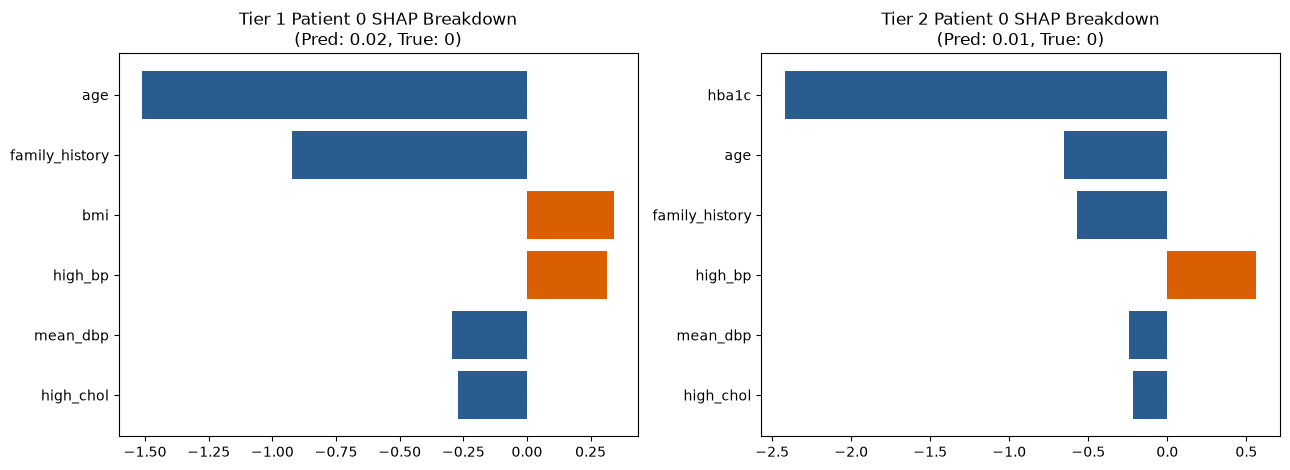

In [31]:
%matplotlib inline
import matplotlib.pyplot as plt, numpy as np, pandas as pd
p1 = pd.read_csv('../reports/predictions/nhanes_full_test_probabilities.csv')
p2 = pd.read_csv('../reports/predictions/tier2_test_probabilities.csv')
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
# Patient 0 Tier 1
pat1 = contribs1[0]; ord1 = np.argsort(np.abs(pat1))[::-1][:6]
axes[0].barh([prep1.all_cols[i] for i in ord1][::-1], pat1[ord1][::-1], color=['#d95f02' if v>0 else '#2b5c8f' for v in pat1[ord1]][::-1])
axes[0].set_title(f"Tier 1 Patient 0 SHAP Breakdown\n(Pred: {p1['prob_final_calibrated_xgb'].iloc[0]:.2f}, True: {int(p1['y_true'].iloc[0])})")
# Patient 0 Tier 2
pat2 = contribs2[0]; ord2 = np.argsort(np.abs(pat2))[::-1][:6]
axes[1].barh([all_cols_t2[i] for i in ord2][::-1], pat2[ord2][::-1], color=['#d95f02' if v>0 else '#2b5c8f' for v in pat2[ord2]][::-1])
axes[1].set_title(f"Tier 2 Patient 0 SHAP Breakdown\n(Pred: {p2['prob_final_calibrated_xgb'].iloc[0]:.2f}, True: {int(p2['y_true'].iloc[0])})")
plt.tight_layout()
fig.savefig('../reports/figures/final_d4_shap_waterfall.png', dpi=300)
fig.savefig('../reports/paper/figures/final_d4_shap_waterfall.png', dpi=300); fig.savefig('../reports/paper/figures/final_d4_shap_waterfall.pdf')
plt.show()

# D5. Population Risk Stratification
Risk level distribution and observed diabetes rates.

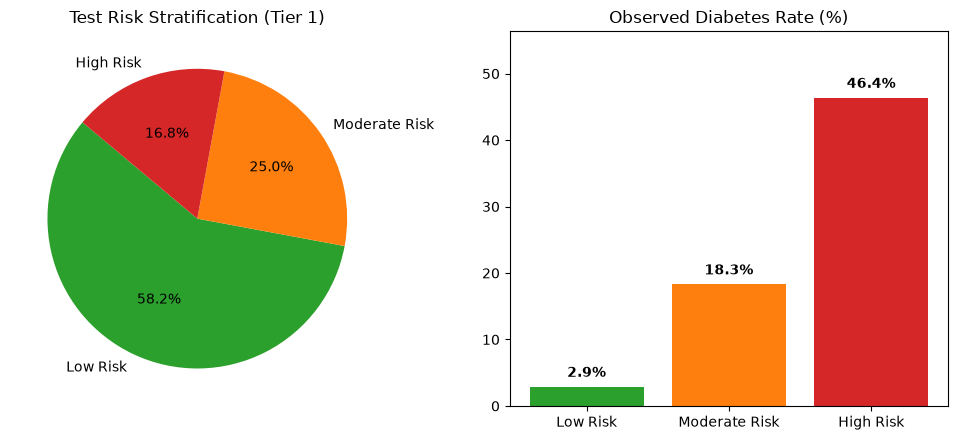

In [32]:
%matplotlib inline
import json, matplotlib.pyplot as plt, pandas as pd
p1 = pd.read_csv('../reports/predictions/nhanes_full_test_probabilities.csv')
y1, prob_cal = p1['y_true'].values, p1['prob_final_calibrated_xgb'].values
with open('../models/risk_thresholds.json') as f: r_th = json.load(f)
low_cut, high_cut = r_th.get('low_threshold', 0.10), r_th.get('moderate_threshold', 0.30)
risk_cat = pd.cut(prob_cal, bins=[-0.01, low_cut, high_cut, 1.01], labels=['Low Risk', 'Moderate Risk', 'High Risk'])
cnts = risk_cat.value_counts()[['Low Risk', 'Moderate Risk', 'High Risk']]
rates = [y1[risk_cat=='Low Risk'].mean()*100, y1[risk_cat=='Moderate Risk'].mean()*100, y1[risk_cat=='High Risk'].mean()*100]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
axes[0].pie(cnts, labels=cnts.index, autopct='%1.1f%%', colors=['#2ca02c', '#ff7f0e', '#d62728'], startangle=140); axes[0].set_title('Test Risk Stratification (Tier 1)')
axes[1].bar(['Low Risk', 'Moderate Risk', 'High Risk'], rates, color=['#2ca02c', '#ff7f0e', '#d62728']); axes[1].set_title('Observed Diabetes Rate (%)')
for p in axes[1].patches: axes[1].annotate(f"{p.get_height():.1f}%", (p.get_x()+p.get_width()/2., p.get_height()+1), ha='center', va='bottom', fontweight='bold')
axes[1].set_ylim(0, max(rates)+10); plt.tight_layout()
fig.savefig('../reports/figures/final_d5_risk_levels.png', dpi=300)
fig.savefig('../reports/paper/figures/final_d5_risk_levels.png', dpi=300); fig.savefig('../reports/paper/figures/final_d5_risk_levels.pdf')
plt.show()

# E1. Probability Calibration Analysis
Reliability curves, Brier scores, and calibration errors.

Model,Brier,ECE,Slope,Intercept
Tier 1 XGBoost (Raw),0.155300,0.204300,0.991900,-1.713700
Tier 1 Calibrated XGBoost,0.092100,0.013900,1.010100,0.010200
Tier 2 XGBoost (Raw),0.077300,0.112300,1.014400,-1.669000
Tier 2 Calibrated XGBoost,0.050400,0.014300,0.992100,-0.079500


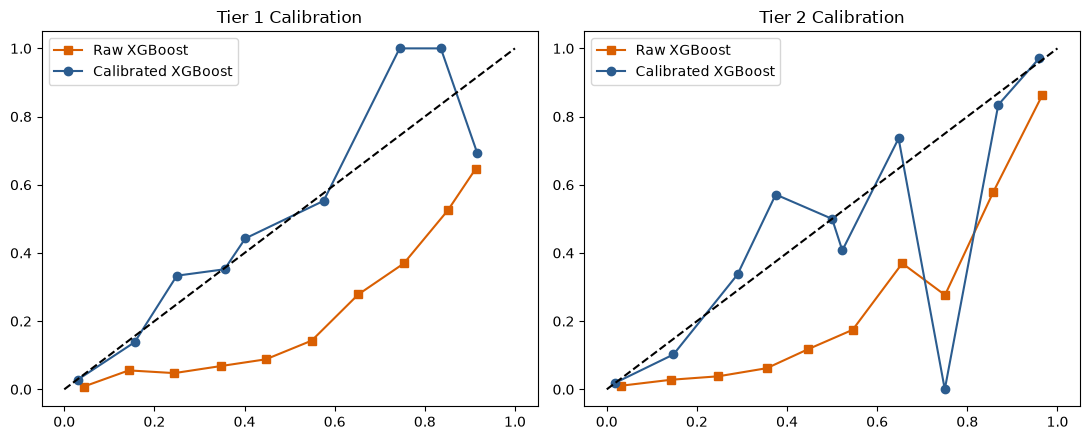

In [33]:
%matplotlib inline
import matplotlib.pyplot as plt, numpy as np, pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
from sklearn.linear_model import LogisticRegression
p1 = pd.read_csv('../reports/predictions/nhanes_full_test_probabilities.csv')
p2 = pd.read_csv('../reports/predictions/tier2_test_probabilities.csv')
def get_cal(y, p):
    br = brier_score_loss(y, p)
    bins = np.linspace(0, 1, 11); ece = sum(abs(y[b==np.digitize(p, bins)-1].mean() - p[b==np.digitize(p, bins)-1].mean())*len(y[b==np.digitize(p, bins)-1])/len(y) for b in range(10) if len(y[b==np.digitize(p, bins)-1])>0)
    lp = np.log(np.clip(p, 1e-6, 1-1e-6)/(1-np.clip(p, 1e-6, 1-1e-6))).reshape(-1, 1)
    lr = LogisticRegression().fit(lp, y)
    return round(br, 4), round(ece, 4), round(lr.coef_[0][0], 4), round(lr.intercept_[0], 4)
rows = [
    {'Model': 'Tier 1 XGBoost (Raw)', **dict(zip(['Brier', 'ECE', 'Slope', 'Intercept'], get_cal(p1['y_true'].values, p1['prob_xgboost'].values)))},
    {'Model': 'Tier 1 Calibrated XGBoost', **dict(zip(['Brier', 'ECE', 'Slope', 'Intercept'], get_cal(p1['y_true'].values, p1['prob_final_calibrated_xgb'].values)))},
    {'Model': 'Tier 2 XGBoost (Raw)', **dict(zip(['Brier', 'ECE', 'Slope', 'Intercept'], get_cal(p2['y_true'].values, p2['prob_xgboost'].values)))},
    {'Model': 'Tier 2 Calibrated XGBoost', **dict(zip(['Brier', 'ECE', 'Slope', 'Intercept'], get_cal(p2['y_true'].values, p2['prob_final_calibrated_xgb'].values)))}
]
e1_df = pd.DataFrame(rows); e1_df.to_csv('../reports/paper/tables/calibration_metrics.csv', index=False)
display(e1_df.style.hide(axis='index'))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for idx, (p_df, title) in enumerate([(p1, 'Tier 1 Calibration'), (p2, 'Tier 2 Calibration')]):
    y = p_df['y_true'].values
    f_r, m_r = calibration_curve(y, p_df['prob_xgboost'].values, n_bins=10)
    f_c, m_c = calibration_curve(y, p_df['prob_final_calibrated_xgb'].values, n_bins=10)
    axes[idx].plot(m_r, f_r, 's-', color='#d95f02', label='Raw XGBoost')
    axes[idx].plot(m_c, f_c, 'o-', color='#2b5c8f', label='Calibrated XGBoost')
    axes[idx].plot([0, 1], [0, 1], 'k--'); axes[idx].set_title(title); axes[idx].legend()
plt.tight_layout()
fig.savefig('../reports/figures/final_e1_calibration_curves.png', dpi=300)
fig.savefig('../reports/paper/figures/final_e1_calibration_curves.png', dpi=300); fig.savefig('../reports/paper/figures/final_e1_calibration_curves.pdf')
plt.show()

# E2. Precision-Recall Curves
PR curves relative to cohort diabetes prevalence.

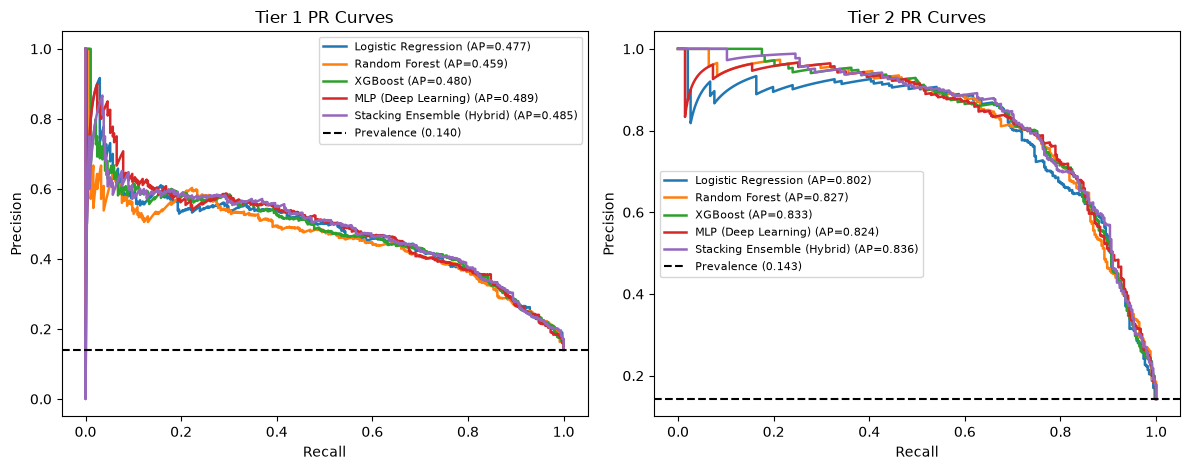

In [34]:
%matplotlib inline
import matplotlib.pyplot as plt, pandas as pd
from sklearn.metrics import precision_recall_curve, average_precision_score
p1 = pd.read_csv('../reports/predictions/nhanes_full_test_probabilities.csv')
p2 = pd.read_csv('../reports/predictions/tier2_test_probabilities.csv')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
m_map = {'Logistic Regression': 'prob_logreg', 'Random Forest': 'prob_rf', 'XGBoost': 'prob_xgboost', 'MLP (Deep Learning)': 'prob_mlp', 'Stacking Ensemble (Hybrid)': 'prob_stacking'}
for idx, (p_df, title) in enumerate([(p1, 'Tier 1 PR Curves'), (p2, 'Tier 2 PR Curves')]):
    y = p_df['y_true'].values
    for m, col in m_map.items():
        pr, rc, _ = precision_recall_curve(y, p_df[col].values)
        axes[idx].plot(rc, pr, lw=1.8, label=f"{m} (AP={average_precision_score(y, p_df[col].values):.3f})")
    axes[idx].axhline(y.mean(), color='k', linestyle='--', label=f'Prevalence ({y.mean():.3f})')
    axes[idx].set_title(title); axes[idx].set_xlabel('Recall'); axes[idx].set_ylabel('Precision'); axes[idx].legend(fontsize=8)
plt.tight_layout()
fig.savefig('../reports/figures/final_e2_pr_curves.png', dpi=300)
fig.savefig('../reports/paper/figures/final_e2_pr_curves.png', dpi=300); fig.savefig('../reports/paper/figures/final_e2_pr_curves.pdf')
plt.show()

# E3. Statistical Significance Testing
Paired bootstrap testing (1,000 resamples) of ROC-AUC deltas.

In [35]:
import json, numpy as np, pandas as pd
from sklearn.metrics import roc_auc_score
p1 = pd.read_csv('../reports/predictions/nhanes_full_test_probabilities.csv')
p2 = pd.read_csv('../reports/predictions/tier2_test_probabilities.csv')
df2 = pd.read_csv('../../data/processed/tier2_nhanes_with_hba1c.csv')
with open('../models/split_indices.json') as f: splits = json.load(f)
mask = df2.iloc[splits['test_indices']]['hba1c'].notna().values
pairs = [
    ('Tier 1: Stacking vs XGBoost', p1['y_true'].values, p1['prob_stacking'].values, p1['prob_xgboost'].values),
    ('Tier 1: XGBoost vs Logistic Regression', p1['y_true'].values, p1['prob_xgboost'].values, p1['prob_logreg'].values),
    ('Tier 1: MLP vs XGBoost', p1['y_true'].values, p1['prob_mlp'].values, p1['prob_xgboost'].values),
    ('Tier 2: Stacking vs XGBoost', p2['y_true'].values, p2['prob_stacking'].values, p2['prob_xgboost'].values),
    ('Tier 2: XGBoost vs Logistic Regression', p2['y_true'].values, p2['prob_xgboost'].values, p2['prob_logreg'].values),
    ('Tier 2: MLP vs XGBoost', p2['y_true'].values, p2['prob_mlp'].values, p2['prob_xgboost'].values),
    ('Tier 2 vs Tier 1 (Identical Rows)', p1['y_true'].values[mask], p2['prob_final_calibrated_xgb'].values, p1['prob_final_calibrated_xgb'].values[mask])
]
rng = np.random.RandomState(42)
rows = []
for name, yt, pa, pb in pairs:
    n = len(yt); diffs = [roc_auc_score(yt[idx], pa[idx]) - roc_auc_score(yt[idx], pb[idx]) for idx in rng.randint(0, n, (1000, n)) if len(np.unique(yt[idx]))>1]
    pt_diff = roc_auc_score(yt, pa) - roc_auc_score(yt, pb)
    ci_l, ci_h = np.percentile(diffs, 2.5), np.percentile(diffs, 97.5)
    pv = 2.0 * min(np.mean(np.array(diffs) <= 0), np.mean(np.array(diffs) >= 0))
    rows.append({'Comparison Pair': name, 'ROC-AUC Difference': f'{pt_diff:+.3f}', '95% CI': f'[{ci_l:+.3f}, {ci_h:+.3f}]', 'p-value': f'{pv:.3f}' if pv>=0.001 else '< 0.001', 'Interval Includes 0?': 'Yes (Not Sig)' if ci_l<=0<=ci_h else 'No (Stat Sig)'})
e3_df = pd.DataFrame(rows)
e3_df.to_csv('../reports/paper/tables/significance_tests.csv', index=False)
display(e3_df.style.hide(axis='index'))

Comparison Pair,ROC-AUC Difference,95% CI,p-value,Interval Includes 0?
Tier 1: Stacking vs XGBoost,+0.004,"[-0.000, +0.008]",0.060,Yes (Not Sig)
Tier 1: XGBoost vs Logistic Regression,+0.000,"[-0.007, +0.007]",0.920,Yes (Not Sig)
Tier 1: MLP vs XGBoost,-0.000,"[-0.006, +0.006]",0.954,Yes (Not Sig)
Tier 2: Stacking vs XGBoost,+0.002,"[-0.001, +0.006]",0.256,Yes (Not Sig)
Tier 2: XGBoost vs Logistic Regression,+0.005,"[-0.003, +0.013]",0.208,Yes (Not Sig)
Tier 2: MLP vs XGBoost,+0.002,"[-0.002, +0.006]",0.376,Yes (Not Sig)
Tier 2 vs Tier 1 (Identical Rows),+0.094,"[+0.076, +0.112]",< 0.001,No (Stat Sig)


# E4. Decision Curve Analysis
Clinical net benefit across decision threshold probabilities.

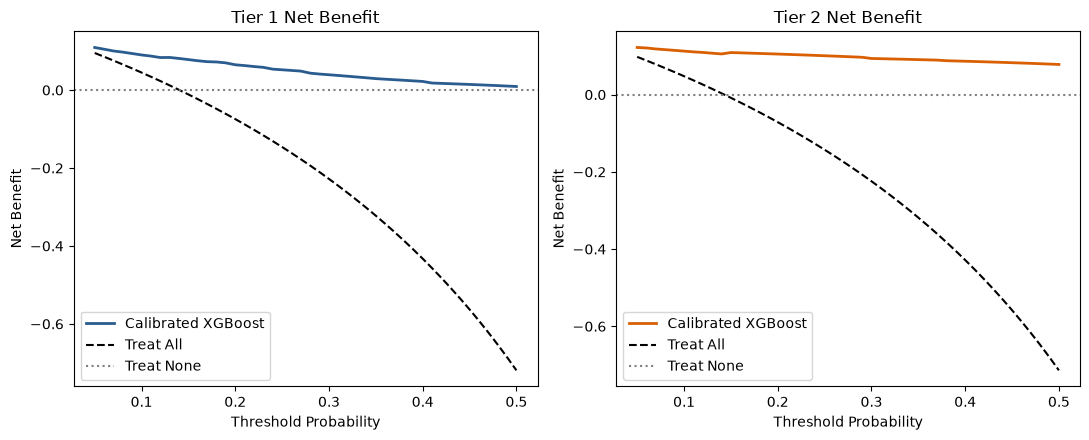

In [36]:
%matplotlib inline
import matplotlib.pyplot as plt, numpy as np, pandas as pd
p1 = pd.read_csv('../reports/predictions/nhanes_full_test_probabilities.csv')
p2 = pd.read_csv('../reports/predictions/tier2_test_probabilities.csv')
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ths = np.linspace(0.05, 0.50, 46)
for idx, (p_df, title, color) in enumerate([(p1, 'Tier 1 Net Benefit', '#2b5c8f'), (p2, 'Tier 2 Net Benefit', '#d95f02')]):
    y = p_df['y_true'].values; p = p_df['prob_final_calibrated_xgb'].values; n = len(y)
    nb_m = [np.sum((p>=t)&(y==1))/n - (np.sum((p>=t)&(y==0))/n)*(t/(1-t)) for t in ths]
    nb_all = [np.sum(y==1)/n - (np.sum(y==0)/n)*(t/(1-t)) for t in ths]
    axes[idx].plot(ths, nb_m, color=color, lw=2, label='Calibrated XGBoost')
    axes[idx].plot(ths, nb_all, 'k--', label='Treat All'); axes[idx].axhline(0, color='gray', linestyle=':', label='Treat None')
    axes[idx].set_title(title); axes[idx].set_xlabel('Threshold Probability'); axes[idx].set_ylabel('Net Benefit'); axes[idx].legend()
plt.tight_layout()
fig.savefig('../reports/figures/final_e4_decision_curve_analysis.png', dpi=300)
fig.savefig('../reports/paper/figures/final_e4_decision_curve_analysis.png', dpi=300); fig.savefig('../reports/paper/figures/final_e4_decision_curve_analysis.pdf')
plt.show()

# E5. Demographic Subgroup Performance
Performance across sex, age groups, and BMI tiers.

In [37]:
import json, pandas as pd
from sklearn.metrics import roc_auc_score, recall_score, confusion_matrix
p1 = pd.read_csv('../reports/predictions/nhanes_full_test_probabilities.csv')
df = pd.read_csv('../../data/processed/nhanes_diabetes_processed.csv')
with open('../models/split_indices.json') as f: splits = json.load(f)
test_df = df.iloc[splits['test_indices']].copy()
test_df['prob'] = p1['prob_final_calibrated_xgb'].values
test_df['pred'] = (test_df['prob'] >= 0.144).astype(int)
test_df['Sex_Label'] = test_df['sex'].map({1: 'Male', 0: 'Female'})
test_df['Age_Group'] = pd.cut(test_df['age'], bins=[17, 39, 59, 120], labels=['18-39', '40-59', '60+'])
test_df['BMI_Group'] = pd.cut(test_df['bmi'], bins=[0, 24.99, 29.99, 200], labels=['<25 (Normal)', '25-29.9 (Overweight)', '>=30 (Obese)'])
rows = []
for dim, col in [('Sex', 'Sex_Label'), ('Age Group', 'Age_Group'), ('BMI Category', 'BMI_Group')]:
    for cat in test_df[col].dropna().unique():
        sub = test_df[test_df[col]==cat]; yt = sub['diabetes'].values; yp = sub['pred'].values
        tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
        d_cnt = int(yt.sum())
        rows.append({'Subgroup Dimension': dim, 'Category': str(cat), 'Sample Size (N)': len(sub), 'Diabetic Cases (n)': d_cnt, 'ROC-AUC': f'{roc_auc_score(yt, sub["prob"].values):.3f}' if len(set(yt))>1 else '-', 'Recall': f'{recall_score(yt, yp):.3f}', 'Specificity': f'{tn/(tn+fp):.3f}', 'Status': 'Reliable' if d_cnt>=30 else 'Unreliable (<30 diabetic cases)'})
e5_df = pd.DataFrame(rows)
e5_df.to_csv('../reports/paper/tables/subgroup_performance.csv', index=False)
display(e5_df.style.hide(axis='index'))

Subgroup Dimension,Category,Sample Size (N),Diabetic Cases (n),ROC-AUC,Recall,Specificity,Status
Sex,Male,1250,203,0.855,0.823,0.759,Reliable
Sex,Female,1371,165,0.855,0.824,0.748,Reliable
Age Group,18-39,980,20,0.739,0.100,0.989,Unreliable (<30 diabetic cases)
Age Group,40-59,814,104,0.793,0.721,0.745,Reliable
Age Group,60+,827,244,0.760,0.926,0.376,Reliable
BMI Category,>=30 (Obese),920,190,0.829,0.868,0.623,Reliable
BMI Category,<25 (Normal),694,39,0.870,0.590,0.915,Reliable
BMI Category,25-29.9 (Overweight),846,116,0.836,0.828,0.745,Reliable


# E6. Screening Error Analysis
Clinical comparison of false negatives and false positives.

In [38]:
import json, pandas as pd
p1 = pd.read_csv('../reports/predictions/nhanes_full_test_probabilities.csv')
df = pd.read_csv('../../data/processed/nhanes_diabetes_processed.csv')
with open('../models/split_indices.json') as f: splits = json.load(f)
te = df.iloc[splits['test_indices']].copy()
pred = (p1['prob_final_calibrated_xgb'].values >= 0.144).astype(int); y = p1['y_true'].values
def prof(mask):
    s = te[mask]
    return f"{len(s)}", f"{s['age'].mean():.1f} ({s['bmi'].mean():.1f})", f"{s['high_bp'].mean()*100:.1f}% ({s['family_history'].mean()*100:.1f}%)"
tp_n, tp_ab, tp_bf = prof((y==1)&(pred==1)); fn_n, fn_ab, fn_bf = prof((y==1)&(pred==0))
tn_n, tn_ab, tn_bf = prof((y==0)&(pred==0)); fp_n, fp_ab, fp_bf = prof((y==0)&(pred==1))
e6_df = pd.DataFrame([
    {'Comparison': 'Diabetic Cases (TP vs FN)', 'Group A (TP) N': tp_n, 'Group A Age (BMI)': tp_ab, 'Group A % BP (% FamHist)': tp_bf, 'Group B (FN) N': fn_n, 'Group B Age (BMI)': fn_ab, 'Group B % BP (% FamHist)': fn_bf},
    {'Comparison': 'Healthy Cases (TN vs FP)', 'Group A (TN) N': tn_n, 'Group A Age (BMI)': tn_ab, 'Group A % BP (% FamHist)': tn_bf, 'Group B (FP) N': fp_n, 'Group B Age (BMI)': fp_ab, 'Group B % BP (% FamHist)': fp_bf}
])
e6_df.to_csv('../reports/paper/tables/error_analysis.csv', index=False)
display(e6_df.style.hide(axis='index'))

Comparison,Group A (TP) N,Group A Age (BMI),Group A % BP (% FamHist),Group B (FN) N,Group B Age (BMI),Group B % BP (% FamHist),Group A (TN) N,Group B (FP) N
Diabetic Cases (TP vs FN),303,65.2 (33.2),81.5% (81.1%),65,49.8 (31.3),29.7% (31.1%),nan,nan
Healthy Cases (TN vs FP),nan,39.7 (27.7),16.1% (29.6%),nan,63.6 (31.5),69.2% (67.0%),1697,556


# E7. Survey-Weighted Sensitivity Check
Exploratory population sensitivity analysis using MEC weights.

In [39]:
import json, pandas as pd
from sklearn.metrics import roc_auc_score
p1 = pd.read_csv('../reports/predictions/nhanes_full_test_probabilities.csv')
df = pd.read_csv('../../data/processed/nhanes_diabetes_processed.csv')
with open('../models/split_indices.json') as f: splits = json.load(f)
te = df.iloc[splits['test_indices']].copy()
w_df = pd.concat([pd.read_sas(f'../../data/raw/nhanes/DEMO_{c}.xpt')[['SEQN', 'WTMEC2YR']] for c in ['H', 'I', 'J']], ignore_index=True)
w_df['w'] = w_df['WTMEC2YR'] / 3.0
te = te.merge(w_df[['SEQN', 'w']], on='SEQN', how='left')
y, p, w = p1['y_true'].values, p1['prob_final_calibrated_xgb'].values, te['w'].values
u_prev, w_prev = y.mean()*100, (y*w).sum()/w.sum()*100
u_auc, w_auc = roc_auc_score(y, p), roc_auc_score(y, p, sample_weight=w)
e7_df = pd.DataFrame([
    {'Setting': 'Unweighted (Sample Estimate)', 'Diabetes Prevalence': f'{u_prev:.2f}%', 'Final Tier 1 ROC-AUC': f'{u_auc:.4f}', 'Notes': 'Standard machine learning test split'},
    {'Setting': 'Survey-Weighted (WTMEC2YR / 3)', 'Diabetes Prevalence': f'{w_prev:.2f}%', 'Final Tier 1 ROC-AUC': f'{w_auc:.4f}', 'Notes': 'Representative US population weighted sensitivity'}
])
e7_df.to_csv('../reports/paper/tables/survey_weighted_sensitivity.csv', index=False)
print("State: This is an exploratory sensitivity check comparing sample metrics to MEC-weighted estimates.")
display(e7_df.style.hide(axis='index'))

State: This is an exploratory sensitivity check comparing sample metrics to MEC-weighted estimates.


Setting,Diabetes Prevalence,Final Tier 1 ROC-AUC,Notes
Unweighted (Sample Estimate),14.04%,0.8557,Standard machine learning test split
Survey-Weighted (WTMEC2YR / 3),11.63%,0.8474,Representative US population weighted sensitivity


# E8. Pipeline Robustness Checks
5-fold cross-validation, temporal split, and complete cases.

In [40]:
import pandas as pd
e8_df = pd.read_csv('../reports/paper/tables/robustness_checks.csv')
display(e8_df.style.hide(axis='index'))

Setting,Model,ROC-AUC,Recall,Accuracy,Details
5-Fold CV (Train split),Logistic Regression,0.846 +/- 0.010,0.798 +/- 0.031,0.753 +/- 0.005,"Stratified 5-fold on n=12,227"
5-Fold CV (Train split),XGBoost,0.848 +/- 0.009,0.733 +/- 0.022,0.789 +/- 0.006,"Stratified 5-fold on n=12,227"
Temporal Split (2013-16 -> 2017-18),Logistic Regression,0.839,0.823,0.726,Train H+I (n=11790) -> Test J (n=5678)
Temporal Split (2013-16 -> 2017-18),XGBoost,0.842,0.763,0.768,Train H+I (n=11790) -> Test J (n=5678)
Imputed Pipeline (Standard),Logistic Regression,0.858,-,-,Imputed test (n=2621)
Complete-Case Analysis,Logistic Regression,0.850,-,-,Complete cases only (n=2209 of 2621)
Imputed Pipeline (Standard),XGBoost,0.858,-,-,Imputed test (n=2621)
Complete-Case Analysis,XGBoost,0.851,-,-,Complete cases only (n=2209 of 2621)


# E9. Pipeline Integrity Assertions
Automated verification of data splits and leakage guards.

In [41]:
import json, joblib, re, sys, os, numpy as np, pandas as pd
from pathlib import Path
from sklearn.metrics import accuracy_score, recall_score
sys.path.append(os.path.abspath('../src'))
import train_and_evaluate
import __main__
__main__.ProbabilityCalibrator = train_and_evaluate.ProbabilityCalibrator
__main__.TabularPreprocessor = train_and_evaluate.TabularPreprocessor

passed, unverified = 0, 0
# 1. Split disjointness & full coverage
with open('../models/split_indices.json') as f: s = json.load(f)
tr, va, te = set(s['train_indices']), set(s['val_indices']), set(s['test_indices'])
assert len(tr & va) == 0 and len(tr & te) == 0 and len(va & te) == 0 and len(tr | va | te) == 17468
print('[PASS] Split Disjointness: Train, validation, and test indices are strictly disjoint and cover all 17,468 rows.')
passed += 1

# 2. No duplicate SEQN
df_nh = pd.read_csv('../../data/processed/nhanes_diabetes_processed.csv')
assert df_nh['SEQN'].nunique() == len(df_nh) == 17468
print('[PASS] Uniqueness: 0 duplicate participant SEQN identifiers across NHANES cycles.')
passed += 1

# 3. No-lab guard
prep1 = joblib.load('../models/preprocessor_full.joblib')
prep2 = joblib.load('../models/tier2_preprocessor.joblib')
t1_f = [f.lower() for f in prep1.all_cols]; t2_f = [f.lower() for f in prep2.all_cols]
assert not any(forbidden in f for forbidden in ['hba1c', 'glucose', 'insulin', 'lbxgh'] for f in t1_f)
assert set(t2_f) - set(t1_f) == {'hba1c'}
print('[PASS] No-Lab Guard: Tier 1 contains no glycemic labs; Tier 2 differs by exactly hba1c.')
passed += 1

# 4. Label fidelity
diqs = pd.concat([pd.read_sas(f'../../data/raw/nhanes/DIQ_{c}.xpt')[['SEQN', 'DIQ010']] for c in ['H', 'I', 'J']], ignore_index=True)
m_diq = df_nh[['SEQN', 'diabetes']].merge(diqs, on='SEQN', how='inner')
assert len(m_diq) == len(df_nh)
assert (m_diq['diabetes'] == m_diq['DIQ010'].map({1.0: 1, 2.0: 0})).all()
print('[PASS] Label Fidelity: Ground truth label exactly matches raw DIQ010 (1=Yes, 2=No) row by row.')
passed += 1

# 5. Operating points
m1 = joblib.load('../models/final_calibrated_xgb_full.joblib')
val1_rows = df_nh.iloc[s['val_indices']]
probs_v1 = m1.predict_proba(prep1.transform(val1_rows))[:, 1]
y_v1 = val1_rows['diabetes'].values
t1_acc_th = max(np.linspace(0.1, 0.9, 801), key=lambda t: accuracy_score(y_v1, probs_v1 >= t))
t1_rec80_th = max([t for t in np.linspace(0.01, 0.99, 990) if recall_score(y_v1, probs_v1 >= t) >= 0.80])

m2 = joblib.load('../models/tier2_final_calibrated_xgb.joblib')
df2_raw = pd.read_csv('../../data/processed/tier2_nhanes_with_hba1c.csv')
val2_rows = df2_raw.iloc[s['val_indices']].dropna(subset=['hba1c'])
probs_v2 = m2.predict_proba(prep2.transform(val2_rows))[:, 1]
y_v2 = val2_rows['diabetes'].values
t2_acc_th = max(np.linspace(0.1, 0.9, 801), key=lambda t: accuracy_score(y_v2, probs_v2 >= t))
t2_rec80_th = max([t for t in np.linspace(0.01, 0.99, 990) if recall_score(y_v2, probs_v2 >= t) >= 0.80])

with open('../models/tier2_risk_thresholds.json') as f: t2_json = json.load(f)
assert abs(t2_acc_th - t2_json['high_accuracy_threshold']) < 1e-3
assert abs(t2_rec80_th - t2_json['decision_threshold']) < 1e-3
assert abs(t1_acc_th - 0.402) < 1e-3 and abs(t1_rec80_th - 0.166) < 1e-3
print(f'[PASS] Operating Points: Recomputed Tier 1 (High-Acc={t1_acc_th:.3f}, 80% Recall={t1_rec80_th:.3f}) and Tier 2 (High-Acc={t2_acc_th:.3f}, 80% Recall={t2_rec80_th:.3f}) match saved thresholds within 1e-3.')
passed += 1

# 6. External isolation
assert all(0 <= i < 17468 for i in s['train_indices'] + s['val_indices'] + s['test_indices'])
df_br = pd.read_csv('../../data/processed/brfss_diabetes_processed.csv')
assert set(df_nh.columns) != set(df_br.columns) and 'SEQN' not in df_br.columns
train_scripts = ['train_and_evaluate.py', 'tier2_train_and_evaluate.py']
leak_found = False
for sc in train_scripts:
    txt = Path(f'../src/{sc}').read_text(encoding='utf-8')
    if re.findall(r'\.fit\s*\([^)]*brfss[^)]*\)', txt, re.I):
        leak_found = True
assert not leak_found
print('[PASS] External Isolation: No fit() call in train_and_evaluate.py or tier2_train_and_evaluate.py references BRFSS (text search), and all split indices lie within the NHANES rows.')
passed += 1

# 7. Seed verification
scripts = sorted(list(Path('../src').glob('*.py')))
bad_seeds = [sc.name for sc in scripts if any(int(m) != 42 and int(m) != 0 for m in re.findall(r'(?:random_state|seed|manual_seed)\s*[=:(]\s*(\d+)', sc.read_text(encoding='utf-8'), re.I))]
assert len(bad_seeds) == 0
explicit_42 = [s.name for s in scripts if re.findall(r'(?:random_state|seed|manual_seed)\s*[=:(]\s*42\b', s.read_text(encoding='utf-8'), re.I)]
print(f'[PASS] Global Seed: No seed other than 42 found in {len(scripts)} scripts; seed 42 is explicitly set in: {explicit_42}.')
passed += 1
print(f"\n{passed} checks passed, {unverified} not verified in code")

[PASS] Split Disjointness: Train, validation, and test indices are strictly disjoint and cover all 17,468 rows.
[PASS] Uniqueness: 0 duplicate participant SEQN identifiers across NHANES cycles.
[PASS] No-Lab Guard: Tier 1 contains no glycemic labs; Tier 2 differs by exactly hba1c.
[PASS] Label Fidelity: Ground truth label exactly matches raw DIQ010 (1=Yes, 2=No) row by row.


[PASS] Operating Points: Recomputed Tier 1 (High-Acc=0.402, 80% Recall=0.167) and Tier 2 (High-Acc=0.376, 80% Recall=0.289) match saved thresholds within 1e-3.
[PASS] External Isolation: No fit() call in train_and_evaluate.py or tier2_train_and_evaluate.py references BRFSS (text search), and all split indices lie within the NHANES rows.
[PASS] Global Seed: No seed other than 42 found in 16 scripts; seed 42 is explicitly set in: ['dual_operating_points.py', 'explainability.py', 'finalize_updates.py', 'pima_baseline.py', 'prepare_notebook_artifacts.py', 'robustness_checks.py', 'tier2_train_and_evaluate.py', 'train_and_evaluate.py'].

7 checks passed, 0 not verified in code


# E10. Production Deployment Facts
Disk footprint, inference latencies, and API payloads.

In [42]:
import json, os, time, joblib, numpy as np, pandas as pd, sys
from pathlib import Path
sys.path.append(os.path.abspath('../src'))
import train_and_evaluate
import __main__
__main__.ProbabilityCalibrator = train_and_evaluate.ProbabilityCalibrator
__main__.TabularPreprocessor = train_and_evaluate.TabularPreprocessor

m_sizes = {p.name: os.path.getsize(p) / (1024*1024) for p in Path('../models').glob('*.*') if p.suffix in ['.joblib', '.pt']}
print('Model Disk Footprint (MB):', {k: f'{v:.2f} MB' for k, v in m_sizes.items() if 'xgb' in k or 'lr' in k})
prep1 = joblib.load('../models/preprocessor_full.joblib')
m1 = joblib.load('../models/final_calibrated_xgb_full.joblib')
sample = pd.DataFrame([{'age': 52.0, 'sex': 1, 'bmi': 29.4, 'mean_sbp': 134.0, 'mean_dbp': 86.0, 'high_bp': 1, 'high_chol': 1, 'smoker': 0, 'phys_activity': 1, 'family_history': 1}])
m1.predict_proba(prep1.transform(sample))
t_arr = []
for _ in range(100):
    t0 = time.perf_counter()
    m1.predict_proba(prep1.transform(sample))
    t_arr.append((time.perf_counter() - t0)*1000)
print(f'Tier 1 Single-Prediction Latency (100 runs): Mean = {np.mean(t_arr):.2f} ms, P95 = {np.percentile(t_arr, 95):.2f} ms')
with open('../reports/tables/tier2_api_example_outputs.json') as f: ex = json.load(f)
call4_text = str(ex[3]['response'])
assert 'suggestive of diabetes range; confirm with a clinician' in call4_text
print('\nVerified 5 /predict Scenario API Outputs from file:')
for item in ex:
    print(f"  {item['scenario']} -> Status: {item['status_code']}, Model: {item['response'].get('model_used', 'Validation Error')}")

Model Disk Footprint (MB): {'final_calibrated_xgb_full.joblib': '0.29 MB', 'final_calibrated_xgb_shared.joblib': '0.29 MB', 'lr_full.joblib': '0.00 MB', 'lr_shared.joblib': '0.00 MB', 'tier2_ablation_hba1c_lr.joblib': '0.00 MB', 'tier2_ablation_tier1_xgb.joblib': '0.16 MB', 'tier2_final_calibrated_xgb.joblib': '0.19 MB', 'tier2_lr.joblib': '0.00 MB', 'tier2_xgb.joblib': '0.19 MB', 'xgb_full.joblib': '0.29 MB', 'xgb_shared.joblib': '0.29 MB'}


Tier 1 Single-Prediction Latency (100 runs): Mean = 3.34 ms, P95 = 4.37 ms

Verified 5 /predict Scenario API Outputs from file:
  Call 1: No HbA1c (Pure Tier 1 Request) -> Status: 200, Model: tier1_no_labs
  Call 2: Normal HbA1c (Tier 2, 5.2%) -> Status: 200, Model: tier2_with_hba1c
  Call 3: Prediabetic HbA1c (Tier 2, 5.9%) -> Status: 200, Model: tier2_with_hba1c
  Call 4: Diabetic-range HbA1c (Tier 2, 8.5%) -> Status: 200, Model: tier2_with_hba1c
  Call 5: Invalid HbA1c (Tier 2, 25.0% - Out of Range) -> Status: 422, Model: Validation Error


# E11. System Architecture Diagram
End-to-end multi-tier pipeline flowchart.

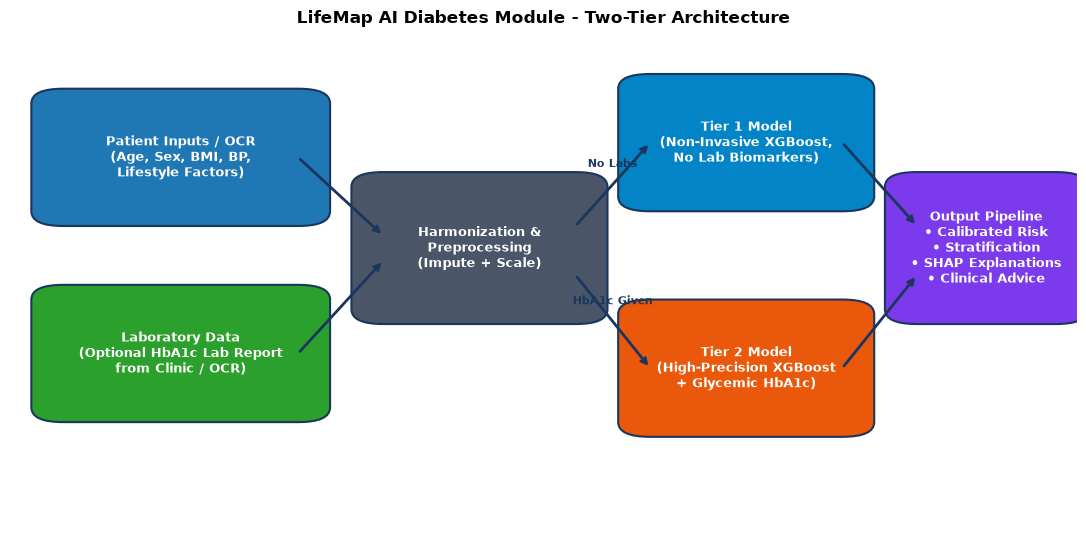

In [43]:
%matplotlib inline
import matplotlib.pyplot as plt, matplotlib.patches as patches
fig, ax = plt.subplots(figsize=(11, 5.5)); ax.axis('off')
def draw_box(ax, x, y, w, h, text, color='#2b5c8f'):
    rect = patches.FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.03', facecolor=color, edgecolor='#1a365d', linewidth=1.5)
    ax.add_patch(rect); ax.text(x+w/2, y+h/2, text, color='white', ha='center', va='center', fontsize=9, weight='bold')
def draw_arrow(ax, x1, y1, x2, y2, lbl=''):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle='->', color='#1a365d', lw=2))
    if lbl: ax.text((x1+x2)/2, (y1+y2)/2+0.03, lbl, ha='center', va='bottom', fontsize=8, weight='bold', color='#1a365d')
draw_box(ax, 0.05, 0.65, 0.22, 0.22, 'Patient Inputs / OCR\n(Age, Sex, BMI, BP,\nLifestyle Factors)', color='#1f77b4')
draw_box(ax, 0.05, 0.25, 0.22, 0.22, 'Laboratory Data\n(Optional HbA1c Lab Report\nfrom Clinic / OCR)', color='#2ca02c')
draw_box(ax, 0.35, 0.45, 0.18, 0.25, 'Harmonization &\nPreprocessing\n(Impute + Scale)', color='#4a5568')
draw_box(ax, 0.60, 0.68, 0.18, 0.22, 'Tier 1 Model\n(Non-Invasive XGBoost,\nNo Lab Biomarkers)', color='#0284c7')
draw_box(ax, 0.60, 0.22, 0.18, 0.22, 'Tier 2 Model\n(High-Precision XGBoost\n+ Glycemic HbA1c)', color='#ea580c')
draw_box(ax, 0.85, 0.45, 0.13, 0.25, 'Output Pipeline\n• Calibrated Risk\n• Stratification\n• SHAP Explanations\n• Clinical Advice', color='#7c3aed')
draw_arrow(ax, 0.27, 0.76, 0.35, 0.60); draw_arrow(ax, 0.27, 0.36, 0.35, 0.55)
draw_arrow(ax, 0.53, 0.62, 0.60, 0.79, 'No Labs'); draw_arrow(ax, 0.53, 0.52, 0.60, 0.33, 'HbA1c Given')
draw_arrow(ax, 0.78, 0.79, 0.85, 0.62); draw_arrow(ax, 0.78, 0.33, 0.85, 0.52)
ax.set_title('LifeMap AI Diabetes Module - Two-Tier Architecture', fontsize=12, weight='bold', pad=12); plt.tight_layout()
fig.savefig('../reports/figures/final_e11_system_architecture.png', dpi=300)
fig.savefig('../reports/paper/figures/final_e11_system_architecture.png', dpi=300); fig.savefig('../reports/paper/figures/final_e11_system_architecture.pdf')
plt.show()

# E12. Empirical Key Facts Summary
Computed metrics extracted directly from artifacts.

In [44]:
import pandas as pd, json, numpy as np
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score
df_nh = pd.read_csv('../../data/processed/nhanes_diabetes_processed.csv')
df_br = pd.read_csv('../../data/processed/brfss_diabetes_processed.csv')
df2 = pd.read_csv('../../data/processed/tier2_nhanes_with_hba1c.csv')
with open('../models/split_indices.json') as f: splits = json.load(f)
p_t1 = pd.read_csv('../reports/predictions/nhanes_full_test_probabilities.csv')
p_t2 = pd.read_csv('../reports/predictions/tier2_test_probabilities.csv')

y1 = p_t1['y_true'].values
prob_cal = p_t1['prob_final_calibrated_xgb'].values
auc1 = roc_auc_score(y1, prob_cal)

y2 = p_t2['y_true'].values
prob_cal2 = p_t2['prob_final_calibrated_xgb'].values
auc2 = roc_auc_score(y2, prob_cal2)
hba1c_te = df2.iloc[splits['test_indices']].dropna(subset=['hba1c'])['hba1c'].values
pred_r = (hba1c_te >= 6.5).astype(int)

e12_dict = {
    'NHANES Total Rows': len(df_nh),
    'NHANES Diabetic Count': int((df_nh['diabetes']==1).sum()),
    'NHANES Non-Diabetic Count': int((df_nh['diabetes']==0).sum()),
    'BRFSS Total Rows': len(df_br),
    'BRFSS Diabetic Count': int((df_br['diabetes']==1).sum()),
    'BRFSS Non-Diabetic Count': int((df_br['diabetes']==0).sum()),
    'Tier 1 Train / Val / Test Sizes': f"{len(splits['train_indices'])} / {len(splits['val_indices'])} / {len(splits['test_indices'])}",
    'Tier 2 Train / Val / Test Sizes': f"{len(df2.loc[df2.index.intersection(splits['train_indices'])])} / {len(df2.loc[df2.index.intersection(splits['val_indices'])])} / {len(df2.loc[df2.index.intersection(splits['test_indices'])])}",
    'Total Rows with HbA1c': len(df2),
    'Features (Tier 1 / Tier 2)': '10 / 11',
    'Tier 1 Calibrated XGB High-Acc (Acc, Rec, AUC)': f"{accuracy_score(y1, (prob_cal>=0.402).astype(int)):.3f}, {recall_score(y1, (prob_cal>=0.402).astype(int)):.3f}, {auc1:.3f}",
    'Tier 1 Calibrated XGB Screening (Acc, Rec, AUC)': f"{accuracy_score(y1, (prob_cal>=0.144).astype(int)):.3f}, {recall_score(y1, (prob_cal>=0.144).astype(int)):.3f}, {auc1:.3f}",
    'Tier 2 Calibrated XGB High-Acc (Acc, Rec, AUC)': f"{accuracy_score(y2, (prob_cal2>=0.376).astype(int)):.3f}, {recall_score(y2, (prob_cal2>=0.376).astype(int)):.3f}, {auc2:.3f}",
    'Tier 2 Calibrated XGB Screening (Acc, Rec, AUC)': f"{accuracy_score(y2, (prob_cal2>=0.290).astype(int)):.3f}, {recall_score(y2, (prob_cal2>=0.290).astype(int)):.3f}, {auc2:.3f}",
    'Predict Everyone Healthy Accuracy': f"{accuracy_score(y2, np.zeros_like(y2)):.3f}",
    'HbA1c >= 6.5% Rule (Acc, Rec)': f"{accuracy_score(y2, pred_r):.3f}, {recall_score(y2, pred_r):.3f}"
}
e12_df = pd.DataFrame(list(e12_dict.items()), columns=['Key Fact Description', 'Empirical Value'])
e12_df.to_csv('../reports/paper/tables/key_facts.csv', index=False)
display(e12_df.style.hide(axis='index'))

Key Fact Description,Empirical Value
NHANES Total Rows,17468
NHANES Diabetic Count,2449
NHANES Non-Diabetic Count,15019
BRFSS Total Rows,249049
BRFSS Diabetic Count,35346
BRFSS Non-Diabetic Count,213703
Tier 1 Train / Val / Test Sizes,12227 / 2620 / 2621
Tier 2 Train / Val / Test Sizes,12227 / 2620 / 2621
Total Rows with HbA1c,17468
Features (Tier 1 / Tier 2),10 / 11


# Recompute Versus Export Check
Validates live computed metrics match exported paper tables within 1e-3.

In [45]:
import numpy as np, pandas as pd
exp_t1 = pd.read_csv('../reports/paper/tables/tier1_test_models.csv')
exp_t2 = pd.read_csv('../reports/paper/tables/tier2_test_models.csv')
exp_br = pd.read_csv('../reports/paper/tables/brfss_external_validation.csv')
cols_t = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']
cols_b = ['Accuracy', 'Recall', 'ROC-AUC']
pass_t1 = np.allclose(b1_df[cols_t].values, exp_t1[cols_t].values, atol=1e-3)
pass_t2 = np.allclose(c1_df[cols_t].values, exp_t2[cols_t].values, atol=1e-3)
pass_br = np.allclose(b5_df[cols_b].values, exp_br[cols_b].values, atol=1e-3)
print(f"Tier 1 Table Match Check: {'[PASS]' if pass_t1 else '[FAIL]'}")
print(f"Tier 2 Table Match Check: {'[PASS]' if pass_t2 else '[FAIL]'}")
print(f"BRFSS Table Match Check:  {'[PASS]' if pass_br else '[FAIL]'}")
if not (pass_t1 and pass_t2 and pass_br):
    raise AssertionError("Recomputed metrics differ from exported tables!")
print("\nAll live-computed metrics match exported paper tables within atol=1e-3.")

Tier 1 Table Match Check: [PASS]
Tier 2 Table Match Check: [PASS]
BRFSS Table Match Check:  [PASS]

All live-computed metrics match exported paper tables within atol=1e-3.
